# Changing strategy - monkey YU

Monkey YU version of `changing_strategy.ipynb`, with the sessions split by injection type (none, sham, DCZ, MISSING = session not in any of the injection date lists):

1. number of switches per session
2. target selection rate and mean reward rate over sessions
3. probability of choosing the best target over sessions
4. reaction time (RT): time between lever validation (62) and lever release after validation (64), log-transformed (natural log of RT in ms)
5. without MISSING sessions: number of events per trial (vigour), early lever releases, late lever touches, early target releases, late target touches in rewarded and not rewarded trials

Statistics (1, 4, 5): sessions are the samples. Two-sided Mann-Whitney U test for every pair of injection types, Holm-corrected for the number of pairs, significant if corrected p < 0.05.

In [1]:
##% imports
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

from popy.io_tools import load_behavior
from popy.behavior_data_tools import add_switch_info, add_trial_in_block, add_date_of_recordig, drop_time_fields
from popy.config import COLORS

# fontsize 8
plt.rcParams.update({'font.size': 8})

# injection types and their colors
INJECTIONS = ['none', 'sham', 'dcz', 'MISSING']
INJECTION_COLORS = {'none': 'grey',          # grey
                    'dcz': '#4CBB17',        # poison green
                    'sham': "#124BA0",       # deep blue
                    'MISSING': '#8B0000'}    # deep red

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-nnbn6z3b because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


In [2]:

def pairwise_tests(sessions, y, order=INJECTIONS):
    """
    Two-sided Mann-Whitney U test of column y between every pair of injection types (sessions are the samples),
    Holm-corrected for the number of pairs. A pair is significant if the corrected p < 0.05.
    """
    rows = []
    for group_1, group_2 in itertools.combinations(order, 2):
        values_1 = sessions.loc[sessions.injection == group_1, y]
        values_2 = sessions.loc[sessions.injection == group_2, y]
        u, p = stats.mannwhitneyu(values_1, values_2, alternative='two-sided')
        rows.append({'group_1': group_1, 'group_2': group_2, 'n_1': len(values_1), 'n_2': len(values_2), 'U': u, 'p': p})

    stats_df = pd.DataFrame(rows)
    stats_df['significant'], stats_df['p_holm'] = multipletests(stats_df['p'], alpha=0.05, method='holm')[:2]

    return stats_df


def plot_box_with_scatter(sessions, y, ax, order=INJECTIONS):
    """
    Boxplot of column y per injection type, with the sessions as scatter points slightly left of the boxes.
    """
    sns.boxplot(data=sessions, x='injection', y=y, order=order,
                hue='injection', hue_order=order, palette=INJECTION_COLORS, legend=False,
                width=0.3, ax=ax,
                boxprops=dict(alpha=0.5, edgecolor='black', linewidth=1.5),
                whiskerprops=dict(color='black', linewidth=1.5),
                capprops=dict(color='black', linewidth=1.5),
                medianprops=dict(color='black', linewidth=1.5),
                showfliers=False)

    # add scatter points slightly to the left of the box
    strip = sns.stripplot(data=sessions, x='injection', y=y, order=order,
                          hue='injection', hue_order=order, palette=INJECTION_COLORS, legend=False,
                          alpha=0.6, size=3, ax=ax, jitter=0.1, zorder=0)

    # shift stripplot points to the left
    for collection in strip.collections:
        offsets = collection.get_offsets()
        offsets[:, 0] = offsets[:, 0] - 0.2  # shift left
        collection.set_offsets(offsets)

    # formatting, with number of sessions per injection type in the tick labels
    n_sessions = sessions.injection.value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f'{injection}\n(n={n_sessions.get(injection, 0)})' for injection in order])
    ax.set_xlabel('')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)


def draw_bracket(ax, x1, x2, y, height, p):
    """
    Draws a significance bracket between x1 and x2 at height y, with stars for the p-value.
    """
    ax.plot([x1, x1, x2, x2], [y - height / 4, y, y, y - height / 4], color='black', linewidth=0.8)
    stars = '***' if p < .001 else '**' if p < .01 else '*'
    ax.text((x1 + x2) / 2, y - height / 8, stars, ha='center', va='bottom')


def add_significance_bars(ax, stats_df, values, order=INJECTIONS):
    """
    Draws a bracket with stars above the boxes for every significant pair (Holm-corrected p < 0.05),
    shorter brackets lower.
    """
    significant = stats_df[stats_df['significant']].copy()
    if significant.empty:
        ax.text(0.5, 1.0, 'all pairs n.s.', transform=ax.transAxes, ha='center', va='bottom')
        return

    significant['x1'] = significant['group_1'].apply(order.index)
    significant['x2'] = significant['group_2'].apply(order.index)
    significant['width'] = significant['x2'] - significant['x1']
    significant = significant.sort_values(['width', 'x1'])

    step = 0.12 * (values.max() - values.min())
    for level, (_, row) in enumerate(significant.iterrows(), start=1):
        draw_bracket(ax, row['x1'], row['x2'], values.max() + level * step, step, row['p_holm'])


def compare_injections(sessions, measures, ncols=4, order=INJECTIONS):
    """
    One boxplot panel per measure ({column of sessions: y label}), with pairwise tests between the injection types.
    Measures that are 0 in every session are only plotted, not tested.
    Returns the figure and the Holm-corrected p-values (rows: pairs of injection types, columns: measures).
    """
    nrows = int(np.ceil(len(measures) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.4 * nrows), squeeze=False)

    p_holm = {}
    for ax, (measure, ylabel) in zip(axs.flat, measures.items()):
        plot_box_with_scatter(sessions, measure, ax, order=order)
        ax.set_ylabel(ylabel)
        if (sessions[measure] == 0).all():
            ax.text(0.5, 1.0, 'never occurs', transform=ax.transAxes, ha='center', va='bottom')
            continue
        stats_df = pairwise_tests(sessions, measure, order=order)
        add_significance_bars(ax, stats_df, sessions[measure], order=order)
        p_holm[measure] = stats_df.set_index(['group_1', 'group_2'])['p_holm']

    # hide unused panels
    for ax in axs.flat[len(measures):]:
        ax.set_visible(False)
    plt.tight_layout()

    return fig, pd.DataFrame(p_holm)


def format_date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%y'))
    for tick in ax.get_xticklabels():
        tick.set_rotation(20)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

In [3]:
# load all sessions of monkey yu
behav = load_behavior('yu')

behav = add_switch_info(behav)
behav = add_trial_in_block(behav)
behav = add_date_of_recordig(behav)
behav['if_best_target'] = behav['target'] == behav['best_target']

# reaction time: lever validation (62) -> lever release after validation (64), log-transformed (natural log of ms)
behav['RT'] = behav['lever_release_time'] - behav['lever_validation_time']
behav['log_RT'] = np.log(behav['RT'] * 1000)

#behav = drop_time_fields(behav)
behav = behav.dropna()

# remove missing injection types (sessions with missing injection type are not included in the analysis)
behav

,date_of_recording,monkey,injection,session,trial_id,trial_start_time,n_target_touches,lever_touch_time,lever_validation_time,lever_release_time,...,n_premature_target_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward,n_false_touch,switch,trial_id_in_block,if_best_target,RT,log_RT
1,2024-02-01,yu,sham,010224,1,6.4813,1.0,6.8342,8.3548,9.1110,...,0,0,0,0,0,0.0,1,False,0.7562,6.628306
2,2024-02-01,yu,sham,010224,2,11.2613,1.0,20.2153,21.7303,22.7729,...,2,0,0,1,5,0.0,2,False,1.0426,6.949473
3,2024-02-01,yu,sham,010224,3,24.9819,1.0,26.3183,27.8279,29.3000,...,1,0,1,0,2,0.0,3,False,1.4721,7.294445
4,2024-02-01,yu,sham,010224,4,31.6706,1.0,32.0304,33.5480,34.2616,...,0,0,0,2,2,0.0,4,False,0.7136,6.570323
5,2024-02-01,yu,sham,010224,5,36.4682,1.0,37.7642,39.2733,40.4253,...,2,0,0,0,2,0.0,5,False,1.1520,7.049255
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41876,2023-10-31,yu,sham,311023,601,5779.2369,2.0,5785.1810,5786.6919,5786.9392,...,0,1,0,0,7,0.0,38,True,0.2473,5.510602
41877,2023-10-31,yu,sham,311023,602,5789.9008,1.0,5790.1894,5791.7055,5792.0469,...,0,0,0,1,1,0.0,39,True,0.3414,5.833055
41878,2023-10-31,yu,sham,311023,603,5794.2158,1.0,5794.5458,5796.0543,5796.3964,...,1,0,1,0,2,0.0,40,True,0.3421,5.835103
41879,2023-10-31,yu,sham,311023,604,5798.5481,1.0,5806.0566,5807.5665,5807.9282,...,0,0,1,0,6,0.0,41,True,0.3617,5.890815


In [4]:
behav[behav['injection'] == 'MISSING']

,date_of_recording,monkey,injection,session,trial_id,trial_start_time,n_target_touches,lever_touch_time,lever_validation_time,lever_release_time,...,n_premature_target_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward,n_false_touch,switch,trial_id_in_block,if_best_target,RT,log_RT
19236,2023-09-19,yu,MISSING,190923,1,11.9297,2.0,15.4041,16.9159,17.2758,...,5,1,0,0,6,0.0,1,True,0.3599,5.885826
19237,2023-09-19,yu,MISSING,190923,2,21.3469,1.0,27.0340,28.5436,28.8606,...,3,0,0,0,4,1.0,2,False,0.3170,5.758902
19238,2023-09-19,yu,MISSING,190923,3,31.0540,2.0,33.4091,34.9256,35.0301,...,1,1,0,2,5,0.0,3,False,0.1045,4.649187
19239,2023-09-19,yu,MISSING,190923,4,37.6195,1.0,39.4778,40.9905,41.0323,...,2,0,0,0,2,0.0,4,False,0.0418,3.732896
19240,2023-09-19,yu,MISSING,190923,5,44.3558,1.0,44.5565,46.0714,46.2338,...,0,0,0,1,1,0.0,5,False,0.1624,5.090062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36983,2023-08-28,yu,MISSING,280823,547,4105.4787,1.0,4111.0858,4112.5992,4117.2731,...,4,0,0,1,8,0.0,36,True,4.6739,8.449749
36984,2023-08-28,yu,MISSING,280823,548,4119.4738,1.0,4121.7612,4123.2794,4123.4321,...,2,0,0,0,4,1.0,37,False,0.1527,5.028475
36985,2023-08-28,yu,MISSING,280823,549,4126.3888,1.0,4126.6187,4128.1276,4128.8609,...,0,0,0,1,2,1.0,38,False,0.7333,6.597555
36986,2023-08-28,yu,MISSING,280823,550,4131.7341,3.0,4131.9405,4133.4580,4135.6787,...,0,2,0,0,2,1.0,39,True,2.2207,7.705578


In [5]:
# one row per session
sessions = behav.groupby('session').agg(
    date=('date_of_recording', 'first'),
    injection=('injection', 'first'),
    n_switches=('switch', 'sum'),
    reward_rate=('feedback', 'mean'),
    p_best_target=('if_best_target', 'mean'),
    log_RT=('log_RT', 'mean'),
).sort_values('date')

# rate of selecting each target
for target in [1, 2, 3]:
    sessions[f'selection_target_{target}'] = (behav['target'] == target).groupby(behav['session']).mean()

# mean number of events and false touches per trial
touch_columns = ['n_events', 'n_early_lever_release', 'n_late_lever_touch', 'n_early_target_release']
sessions = sessions.join(behav.groupby('session')[touch_columns].mean())

# late target touches after reward / after no reward: mean per rewarded / not rewarded trial
sessions['n_late_target_touch_after_reward'] = behav[behav['feedback'] == 1].groupby('session')['n_late_target_touch_after_reward'].mean()
sessions['n_late_target_touch_after_no_reward'] = behav[behav['feedback'] == 0].groupby('session')['n_late_target_touch_after_no_reward'].mean()

sessions

,date,injection,n_switches,reward_rate,p_best_target,log_RT,selection_target_1,selection_target_2,selection_target_3,n_events,n_early_lever_release,n_late_lever_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward
session,,,,,,,,,,,,,,,
210823,2023-08-21,MISSING,132.0,0.571669,0.693086,5.213426,0.256324,0.322091,0.421585,22.160202,1.016863,0.0,0.588533,0.383481,0.437008
220823,2023-08-22,MISSING,96.0,0.607985,0.720508,5.223699,0.232305,0.382940,0.384755,23.112523,0.994555,0.0,0.477314,0.465672,0.444444
230823,2023-08-23,MISSING,96.0,0.598628,0.720412,5.178350,0.252144,0.336192,0.411664,22.217839,0.789022,0.0,0.444254,0.481375,0.576923
250823,2023-08-25,MISSING,93.0,0.618875,0.738657,5.484800,0.237750,0.335753,0.426497,23.047187,0.809437,0.0,0.724138,0.554252,0.585714
280823,2023-08-28,MISSING,90.0,0.606557,0.706740,5.209114,0.236794,0.324226,0.438980,23.506375,1.418944,0.0,0.506375,0.447447,0.402778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310124,2024-01-31,dcz,58.0,0.644401,0.766208,5.506519,0.249509,0.373281,0.377210,21.151277,0.954813,0.0,0.396857,0.384146,0.767956
010224,2024-02-01,sham,67.0,0.647638,0.801181,6.167101,0.275591,0.356299,0.368110,19.255906,0.517717,0.0,0.206693,0.516717,0.748603
050224,2024-02-05,none,58.0,0.658777,0.786982,5.583771,0.280079,0.291913,0.428008,22.461538,1.274162,0.0,0.301775,0.505988,0.924855


## (1) Number of switches per session

Number of switch trials per session:
	none: 97.22 ± 30.95 switches per session (n=23)
	sham: 81.26 ± 26.18 switches per session (n=23)
	dcz: 79.80 ± 25.41 switches per session (n=20)
	MISSING: 106.67 ± 15.61 switches per session (n=9)

Pairwise Mann-Whitney U tests (Holm-corrected):
group_1 group_2  n_1  n_2     U      p  significant  p_holm
   none    sham   23   23 353.5 0.0518        False  0.2070
   none     dcz   23   20 306.0 0.0658        False  0.2070
   none MISSING   23    9  77.5 0.2847        False  0.5695
   sham     dcz   23   20 238.0 0.8550        False  0.8550
   sham MISSING   23    9  29.5 0.0021         True  0.0123
    dcz MISSING   20    9  33.0 0.0077         True  0.0385


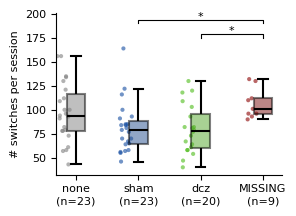

In [6]:
# create boxplot with scatter points for number of switches per session
fig, ax = plt.subplots(1, 1, figsize=(3, 2.2))

plot_box_with_scatter(sessions, 'n_switches', ax)
switch_stats = pairwise_tests(sessions, 'n_switches')
add_significance_bars(ax, switch_stats, sessions['n_switches'])

ax.set_ylabel('# switches per session')
plt.tight_layout()

# print statistics
print('Number of switch trials per session:')
for injection in INJECTIONS:
    values = sessions.loc[sessions.injection == injection, 'n_switches']
    print(f'\t{injection}: {values.mean():.2f} ± {values.std():.2f} switches per session (n={len(values)})')
print('\nPairwise Mann-Whitney U tests (Holm-corrected):')
print(switch_stats.round(4).to_string(index=False))

# save as svg, 300 dpi
plt.savefig('figs/yu_number_of_switches_per_session.svg', dpi=300)

## (2) Target selection and mean reward rate

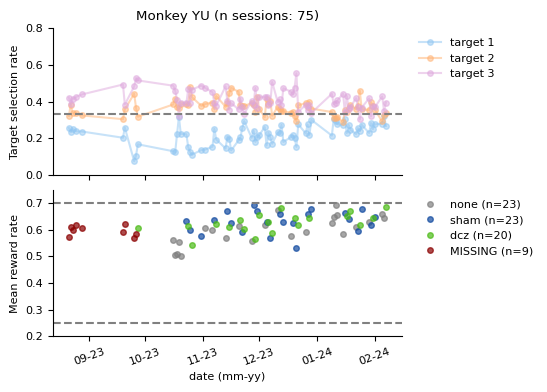

In [7]:
# target selection: all sessions together, mean reward rate: colored by injection type
fig, axs = plt.subplots(2, 1, figsize=(4.5, 4), sharex=True, gridspec_kw={'hspace': 0.1})

# target selection rate
ax = axs[0]
for target in [1, 2, 3]:
    ax.plot(sessions['date'], sessions[f'selection_target_{target}'], marker='o', alpha=.5, label=f'target {target}',
            color=COLORS[f'target_{target}'], markersize=4)
ax.set_title(f'Monkey YU (n sessions: {len(sessions)})')
ax.axhline(1/3, color='gray', linestyle='--')
ax.set_ylim(0, .8)
ax.set_ylabel('Target selection rate')
format_date_axis(ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1, frameon=False)

# mean reward rate
ax = axs[1]
for injection in INJECTIONS:
    session_inj = sessions[sessions.injection == injection]
    ax.plot(session_inj['date'], session_inj['reward_rate'], 'o', color=INJECTION_COLORS[injection], markersize=4, alpha=.7,
            label=f'{injection} (n={len(session_inj)})')
ax.axhline(.25, color='gray', linestyle='--')
ax.axhline(.7, color='gray', linestyle='--')
ax.set_ylim(.20, .75)
ax.set_ylabel('Mean reward rate')
ax.set_xlabel('date (mm-yy)')
format_date_axis(ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1, frameon=False)

# save as png, 300 dpi
fig.savefig('figs/yu_changing_strategy.png', dpi=300, bbox_inches='tight')

## (3) Probability of choosing the best target

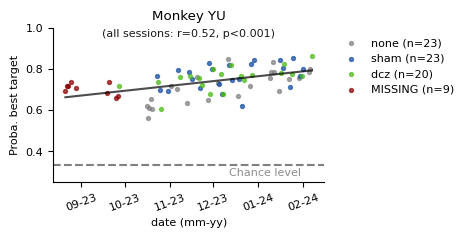

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

for injection in INJECTIONS:
    session_inj = sessions[sessions.injection == injection]
    ax.scatter(session_inj['date'], session_inj['p_best_target'], color=INJECTION_COLORS[injection], alpha=.7, s=8,
               label=f'{injection} (n={len(session_inj)})')

# fit linear regression line over all sessions, show line and add stats in title
x = sessions['date'].values.astype('datetime64[D]').astype(int)
y = sessions['p_best_target'].values
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
x_fit = np.array([x.min(), x.max()])
ax.plot(x_fit.astype('datetime64[D]'), intercept + slope * x_fit, color='black', alpha=0.7)

ax.set_title('Monkey YU')
p_text = 'p<0.001' if p_value < .001 else f'p={p_value:.3f}'
ax.text(0.5, .93, f'(all sessions: r={r_value:.2f}, {p_text})',
        transform=ax.transAxes, ha='center', va='bottom', color='black', fontsize=8, alpha=0.9)
ax.set_xlabel('date (mm-yy)')
ax.set_ylabel('Proba. best target')
format_date_axis(ax)

ax.axhline(1/3, linestyle='dashed', color='grey')
# print chance level on the grey one
ax.text(0.78, .03, 'Chance level', transform=ax.transAxes, ha='center', va='bottom', color='grey', fontsize=8, alpha=0.9)
ax.set_ylim(.25, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1, frameon=False)

# save as svg, 300 dpi
plt.savefig('figs/yu_proba_best_target_over_time.svg', dpi=300, bbox_inches='tight')

## (4) Reaction time

Mean log RT per session (geometric mean RT in brackets):
	none: 5.587 ± 0.192 ln ms (267 ms, n=23)
	sham: 5.680 ± 0.191 ln ms (293 ms, n=23)
	dcz: 5.332 ± 0.161 ln ms (207 ms, n=20)
	MISSING: 5.303 ± 0.136 ln ms (201 ms, n=9)

Pairwise Mann-Whitney U tests (Holm-corrected):
group_1 group_2  n_1  n_2     U      p  significant  p_holm
   none    sham   23   23 176.0 0.0532        False  0.1064
   none     dcz   23   20 394.0 0.0001         True  0.0003
   none MISSING   23    9 186.0 0.0006         True  0.0018
   sham     dcz   23   20 421.0 0.0000         True  0.0000
   sham MISSING   23    9 197.0 0.0001         True  0.0004
    dcz MISSING   20    9  99.0 0.6886        False  0.6886


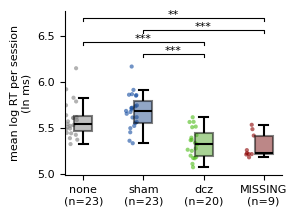

In [9]:
# create boxplot with scatter points for mean log RT per session
fig, ax = plt.subplots(1, 1, figsize=(3, 2.2))

plot_box_with_scatter(sessions, 'log_RT', ax)
rt_stats = pairwise_tests(sessions, 'log_RT')
add_significance_bars(ax, rt_stats, sessions['log_RT'])

ax.set_ylabel('mean log RT per session\n(ln ms)')
plt.tight_layout()

# print statistics
print('Mean log RT per session (geometric mean RT in brackets):')
for injection in INJECTIONS:
    values = sessions.loc[sessions.injection == injection, 'log_RT']
    print(f'\t{injection}: {values.mean():.3f} ± {values.std():.3f} ln ms ({np.exp(values.mean()):.0f} ms, n={len(values)})')
print('\nPairwise Mann-Whitney U tests (Holm-corrected):')
print(rt_stats.round(4).to_string(index=False))

# save as svg, 300 dpi
plt.savefig('figs/yu_reaction_time.svg', dpi=300)

## (5) Number of events and false touches per trial

MISSING sessions are excluded from this analysis. Mean per completed trial, per session. Extracted from the raw events by `popy.behavior_data_tools.get_behavior_yuri()` (event codes: `data/code_LUV_task.txt`):
- number of events: all events between trial start (100) and trial end (101), as a measure of vigour
- early lever release: lever touch (61) released before lever validation (63), i.e. not followed by validation (62)
- late lever touch: lever touch (61) after lever validation (62)
- early target release: target touch (121/122/123) released before target validation (124), i.e. not followed by validation (125)
- late target touch, rewarded / not rewarded: target touch after target validation (131-136, during END 141-143, or 121/122/123 after the 125), mean per rewarded / not rewarded trial. The outcome is taken from the 65 code of the trial (for the END touches, this is the feedback before the touch), because the codes after no reward (134-136) are never sent in this data and 131-133 are sent after both outcomes.

n_events, mean per trial (mean ± std over sessions):
             mean    std
injection               
none       22.021  1.864
sham       20.654  0.904
dcz        22.168  1.060
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
                 n_events
group_1 group_2          
none    sham       0.0245
        dcz        0.5672
sham    dcz        0.0001


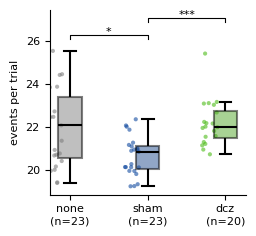

n_early_lever_release, mean per trial (mean ± std over sessions):
            mean    std
injection              
none       0.949  0.367
sham       0.697  0.209
dcz        0.983  0.174
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
                 n_early_lever_release
group_1 group_2                       
none    sham                    0.0245
        dcz                     0.1689
sham    dcz                     0.0003


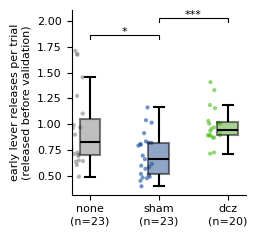

n_late_lever_touch, mean per trial (mean ± std over sessions):
           mean  std
injection           
none        0.0  0.0
sham        0.0  0.0
dcz         0.0  0.0
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
never occurs, not tested


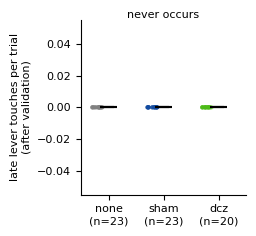

n_early_target_release, mean per trial (mean ± std over sessions):
            mean    std
injection              
none       0.362  0.124
sham       0.388  0.117
dcz        0.492  0.153
Pairwise Mann-Whitney U tests, Holm-corrected p-values:
                 n_early_target_release
group_1 group_2                        
none    sham                     0.2533
        dcz                      0.0053
sham    dcz                      0.0318


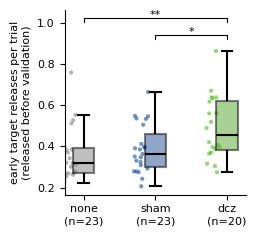

In [10]:
# MISSING sessions are excluded from this analysis
INJECTIONS_5 = ['none', 'sham', 'dcz']
sessions_5 = sessions[sessions.injection.isin(INJECTIONS_5)]

# one figure per measure
measures_5 = {
    'n_events': ('events per trial', 'figs/yu_events_per_trial.svg'),
    'n_early_lever_release': ('early lever releases per trial\n(released before validation)', 'figs/yu_early_lever_releases.svg'),
    'n_late_lever_touch': ('late lever touches per trial\n(after validation)', 'figs/yu_late_lever_touches.svg'),
    'n_early_target_release': ('early target releases per trial\n(released before validation)', 'figs/yu_early_target_releases.svg'),
}
for measure, (ylabel, fname) in measures_5.items():
    fig, p_holm = compare_injections(sessions_5, {measure: ylabel}, ncols=1, order=INJECTIONS_5)

    # print statistics
    print(f'{measure}, mean per trial (mean ± std over sessions):')
    print(sessions_5.groupby('injection')[measure].agg(['mean', 'std']).loc[INJECTIONS_5].round(3).to_string())
    print('Pairwise Mann-Whitney U tests, Holm-corrected p-values:')
    print(p_holm.round(4).to_string() if not p_holm.empty else 'never occurs, not tested')

    # save as svg, 300 dpi
    plt.savefig(fname, dpi=300)
    plt.show()

Late target touches, mean per rewarded / not rewarded trial (mean ± std over sessions):
          n_late_target_touch_after_reward        n_late_target_touch_after_no_reward       
                                      mean    std                                mean    std
injection                                                                                   
none                                 0.503  0.104                               0.675  0.160
sham                                 0.512  0.089                               0.774  0.170
dcz                                  0.435  0.079                               0.707  0.158

Between injection types, rewarded trials (Mann-Whitney U, Holm-corrected):
group_1 group_2  n_1  n_2   U       p  significant  p_holm
   none    sham   23   23 233   0.496        False   0.496
   none     dcz   23   20 320  0.0293        False  0.0586
   sham     dcz   23   20 343 0.00616         True  0.0185

Between injection types, not rewarded tri

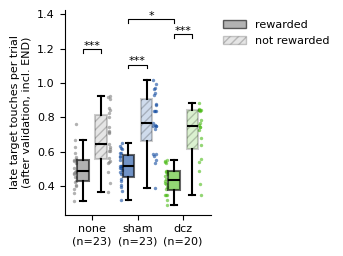

In [11]:
# late target touches per rewarded and per not rewarded trial, in one plot
outcomes = {'n_late_target_touch_after_reward': dict(label='rewarded', offset=-0.2, alpha=0.6, hatch=None),
            'n_late_target_touch_after_no_reward': dict(label='not rewarded', offset=0.2, alpha=0.2, hatch='////')}

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.6))
rng = np.random.default_rng(0)  # jitter of the scatter points
for measure, style in outcomes.items():
    for i, injection in enumerate(INJECTIONS_5):
        values = sessions_5.loc[sessions_5.injection == injection, measure]
        x = i + style['offset']
        ax.boxplot(values, positions=[x], widths=0.25, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=INJECTION_COLORS[injection], alpha=style['alpha'], hatch=style['hatch'],
                                 edgecolor='black', linewidth=1.5),
                   whiskerprops=dict(color='black', linewidth=1.5),
                   capprops=dict(color='black', linewidth=1.5),
                   medianprops=dict(color='black', linewidth=1.5))
        # scatter points next to the box, on the outer side
        ax.scatter(x + np.sign(style['offset']) * 0.17 + rng.uniform(-0.03, 0.03, len(values)), values, color=INJECTION_COLORS[injection], alpha=0.6, s=6,
                   linewidths=0)

# between injection types, separately for rewarded and not rewarded trials (Holm-corrected for the 3 pairs)
between_stats = {measure: pairwise_tests(sessions_5, measure, order=INJECTIONS_5) for measure in outcomes}
# rewarded vs not rewarded trials within each injection type: Wilcoxon signed-rank test, sessions are paired
# (Holm-corrected for the 3 injection types)
within_stats = pd.DataFrame([{'injection': injection,
                              'p': stats.wilcoxon(*[sessions_5.loc[sessions_5.injection == injection, measure] for measure in outcomes]).pvalue}
                             for injection in INJECTIONS_5])
within_stats['significant'], within_stats['p_holm'] = multipletests(within_stats['p'], alpha=0.05, method='holm')[:2]

# significance brackets, shorter brackets lower
brackets = [(i + outcomes['n_late_target_touch_after_reward']['offset'], i + outcomes['n_late_target_touch_after_no_reward']['offset'], row['p_holm'])
            for i, row in within_stats.iterrows() if row['significant']]
for measure, style in outcomes.items():
    for _, row in between_stats[measure][between_stats[measure]['significant']].iterrows():
        brackets.append((INJECTIONS_5.index(row['group_1']) + style['offset'], INJECTIONS_5.index(row['group_2']) + style['offset'], row['p_holm']))
values = sessions_5[list(outcomes)].values
step = 0.12 * (values.max() - values.min())
for level, (x1, x2, p) in enumerate(sorted(brackets, key=lambda bracket: (bracket[1] - bracket[0], bracket[0])), start=1):
    draw_bracket(ax, x1, x2, values.max() + level * step, step, p)
if not brackets:
    ax.text(0.5, 1.0, 'all pairs n.s.', transform=ax.transAxes, ha='center', va='bottom')

# formatting, with number of sessions per injection type in the tick labels
n_sessions = sessions_5.injection.value_counts()
ax.set_xticks(range(len(INJECTIONS_5)))
ax.set_xticklabels([f'{injection}\n(n={n_sessions[injection]})' for injection in INJECTIONS_5])
ax.set_xlim(-0.6, len(INJECTIONS_5) - 0.4)
ax.set_ylabel('late target touches per trial\n(after validation, incl. END)')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.legend(handles=[Patch(facecolor='grey', alpha=style['alpha'], hatch=style['hatch'], edgecolor='black', label=style['label'])
                   for style in outcomes.values()], loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.tight_layout()

# print statistics
print('Late target touches, mean per rewarded / not rewarded trial (mean ± std over sessions):')
print(sessions_5.groupby('injection')[list(outcomes)].agg(['mean', 'std']).loc[INJECTIONS_5].round(3).to_string())
for measure, style in outcomes.items():
    print(f'\nBetween injection types, {style["label"]} trials (Mann-Whitney U, Holm-corrected):')
    print(between_stats[measure].to_string(index=False, float_format='{:.3g}'.format))
print('\nRewarded vs not rewarded trials within injection type (Wilcoxon signed-rank, Holm-corrected):')
print(within_stats.to_string(index=False, float_format='{:.3g}'.format))

# save as svg, 300 dpi
plt.savefig('figs/yu_late_target_touches.svg', dpi=300)

## (6) Effects of the chemogenetic activation of the LC/NA→MCC pathway (DCZ)

DCZ activates the DREADD-expressing noradrenergic (LC) neurons that project to the MCC. The hypotheses tested below are listed, with their literature background and the results, in the report at the end of the notebook.

Approach:
- Primary contrast: **DCZ vs sham** (saline injection) sessions. DCZ and sham days alternate within the same weeks (Tue/Thu sham, Wed/Fri DCZ), so they share the period of training and the injection procedure. *None* sessions are shown for reference only: most of them are Mondays after the weekend break, so they differ from the injection days in more than the injection. MISSING sessions are excluded.
- Unit of analysis: the session (one value per session), completed trials only.
- Test: two-sided Mann-Whitney U, effect size: rank-biserial correlation r (r > 0: larger under DCZ). Robustness check: OLS of the session values on DCZ, session date and weekday (sham and DCZ sessions only).
- All DCZ vs sham tests are collected in a summary table with Benjamini-Hochberg FDR correction (q).

In [12]:
# (6) helpers
import statsmodels.formula.api as smf
from scipy import optimize
from popy.behavior_data_tools import load_raw_behav_csv_yuri
from popy.io_tools_helpers import reformat_behav

DCZ_ORDER = ['none', 'sham', 'dcz']  # MISSING sessions are excluded, as in (5)
DCZ_RESULTS = {}                     # DCZ vs sham tests, {(hypothesis, measure): result}, for the summary table


def get_trial_timing(session):
    '''
    Event times that the preprocessing does not keep, from the raw events of one session. Per trial: lever available
    (first 60), first lever touch (first 61), first target touch after the lever release. Per lever touch: the hold
    duration, until the release before validation (61 -> 63) or the release after validation (61 -> 62 -> 64).
    '''
    raw = load_raw_behav_csv_yuri(session).to_numpy()
    trials, holds = [], []
    for trial_events in reformat_behav(raw)['behav_events']:
        codes, times = trial_events[:, 0].astype(int), trial_events[:, 1]
        start = round(times[0], 4)
        i_release = np.argmax(codes == 64) if (codes == 64).any() else len(codes)
        is_target_touch_after_release = np.isin(codes, [121, 122, 123]) & (np.arange(len(codes)) > i_release)
        trials.append({'session': session, 'trial_start_time': start,
                       'lever_on_time': times[np.argmax(codes == 60)] if (codes == 60).any() else np.nan,
                       'first_lever_touch_time': times[np.argmax(codes == 61)] if (codes == 61).any() else np.nan,
                       'first_target_touch_time': times[np.argmax(is_target_touch_after_release)] if is_target_touch_after_release.any() else np.nan})
        for i in np.where(codes[:-1] == 61)[0]:
            if codes[i + 1] == 63:
                holds.append({'session': session, 'trial_start_time': start, 'hold': times[i + 1] - times[i], 'validated': False})
            elif codes[i + 1] == 62 and (codes[i + 1:] == 64).any():
                i_64 = i + 1 + np.argmax(codes[i + 1:] == 64)
                holds.append({'session': session, 'trial_start_time': start, 'hold': times[i_64] - times[i], 'validated': True})
    return pd.DataFrame(trials), pd.DataFrame(holds)


def dcz_test(sessions, measure):
    '''
    DCZ vs sham sessions: two-sided Mann-Whitney U test and rank-biserial correlation (r > 0: larger under DCZ), and
    the p-value of DCZ in an OLS adjusted for the session date and weekday (sham and DCZ sessions only).
    '''
    values = sessions.dropna(subset=[measure])
    dcz, sham = values.loc[values.injection == 'dcz', measure], values.loc[values.injection == 'sham', measure]
    u, p = stats.mannwhitneyu(dcz, sham, alternative='two-sided')
    data = values[values.injection.isin(['sham', 'dcz'])].assign(is_dcz=lambda df: (df.injection == 'dcz').astype(float))
    ols = smf.ols(f'{measure} ~ is_dcz + days + weekday', data=data).fit()
    return {'measure': measure, 'median_none': values.loc[values.injection == 'none', measure].median(),
            'median_sham': sham.median(), 'median_dcz': dcz.median(),
            'r': 2 * u / (len(dcz) * len(sham)) - 1, 'p': p, 'p_adjusted_ols': ols.pvalues['is_dcz']}


def plot_dcz_panel(ax, sessions, measure, ylabel, hypothesis):
    '''
    Boxplot of a session measure (none, sham, DCZ), titled with the DCZ vs sham test, which is stored in DCZ_RESULTS.
    '''
    plot_box_with_scatter(sessions, measure, ax, order=DCZ_ORDER)
    result = dcz_test(sessions, measure)
    DCZ_RESULTS[(hypothesis, measure)] = result
    ax.set_ylabel(ylabel)
    ax.set_title(f'{hypothesis}: DCZ vs sham p={result["p"]:.2g}, r={result["r"]:+.2f}', fontsize=7)
    return result


def plot_condition_lines(ax, data, x, y, label_suffix=''):
    '''
    Mean ± SEM over sessions of y as a function of x, one line per condition (data: one row per session and x).
    '''
    for injection in DCZ_ORDER:
        stats_x = data[data.injection == injection].groupby(x)[y].agg(['mean', 'sem'])
        ax.plot(stats_x.index, stats_x['mean'], color=INJECTION_COLORS[injection], label=f'{injection}{label_suffix}')
        ax.fill_between(stats_x.index, stats_x['mean'] - stats_x['sem'], stats_x['mean'] + stats_x['sem'],
                        color=INJECTION_COLORS[injection], alpha=0.2, linewidth=0)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

In [13]:
# trial-level data: completed trials of the none, sham and DCZ sessions (interrupted trials excluded, as in the
# foraging paper), switches relative to the previous completed trial
dcz_trials = load_behavior('yu')
dcz_trials = dcz_trials[dcz_trials.injection.isin(DCZ_ORDER) & dcz_trials.target.notna()]
dcz_trials = add_trial_in_block(add_switch_info(dcz_trials))

# event timings and lever holds from the raw events (~30 s)
timing, holds = map(pd.concat, zip(*[get_trial_timing(session) for session in dcz_trials.session.unique()]))
dcz_trials['trial_start_time'] = dcz_trials['trial_start_time'].round(4)
dcz_trials = dcz_trials.merge(timing, on=['session', 'trial_start_time'], how='left', validate='one_to_one')
dcz_holds = holds.merge(dcz_trials[['session', 'trial_start_time', 'injection']], on=['session', 'trial_start_time'])  # holds of the analysed trials

# trial measures
dcz_trials['log_rt'] = np.log((dcz_trials['lever_release_time'] - dcz_trials['lever_validation_time']) * 1000)  # RT, as in (4)
dcz_trials['log_mt'] = np.log((dcz_trials['first_target_touch_time'] - dcz_trials['lever_release_time']) * 1000)  # movement time
dcz_trials['initiation'] = dcz_trials['first_lever_touch_time'] - dcz_trials['lever_on_time']  # lever available -> first touch
dcz_trials['log_initiation'] = np.log(dcz_trials['initiation'] * 1000)
dcz_trials['pause'] = (dcz_trials['initiation'] > 5).astype(float)  # more than 5 s before touching the lever
dcz_trials['best'] = (dcz_trials['target'] == dcz_trials['best_target']).astype(float)
dcz_trials['prev_feedback'] = dcz_trials.groupby('session')['feedback'].shift(1)
dcz_trials['session_fraction'] = dcz_trials.groupby('session').cumcount() / dcz_trials.groupby('session')['session'].transform('size')
dcz_trials['session_quarter'] = np.minimum((dcz_trials['session_fraction'] * 4).astype(int), 3) + 1


def release_hazard(holds, start, stop):
    '''P(lever released before validation within [start, stop) s of holding | held until start).'''
    at_risk = holds['hold'] >= start
    return (at_risk & (holds['hold'] < stop) & ~holds['validated']).sum() / at_risk.sum()


# one row per session
by_session = dcz_trials.groupby('session')
dcz_sessions = pd.DataFrame({
    'injection': by_session['injection'].first(),
    'date': pd.to_datetime(by_session['session'].first(), format='%d%m%y'),
    'log_rt': by_session['log_rt'].median(),
    'log_mt': by_session['log_mt'].median(),
    'log_initiation': by_session['log_initiation'].median(),
    'pause_rate': by_session['pause'].mean(),
    'trials_per_min': by_session.size() / ((by_session['trial_end_time'].max() - by_session['trial_start_time'].min()) / 60),
    'p_best': by_session['best'].mean(),
    'reward_rate': by_session['feedback'].mean(),
})
dcz_sessions['days'] = (dcz_sessions['date'] - dcz_sessions['date'].min()).dt.days
dcz_sessions['weekday'] = dcz_sessions['date'].dt.dayofweek
by_session_holds = dcz_holds.groupby('session')
dcz_sessions['slip_hazard'] = by_session_holds.apply(release_hazard, 0, 0.25)          # release in the first 250 ms
dcz_sessions['late_release_hazard'] = by_session_holds.apply(release_hazard, 1.0, 1.5)  # release in the last 500 ms before validation
dcz_sessions['early_lever_release'] = by_session['n_early_lever_release'].mean()

print(dcz_sessions.groupby('injection').size().loc[DCZ_ORDER].to_string())
dcz_sessions.head()

injection
none    23
sham    23
dcz     20


,injection,date,log_rt,log_mt,log_initiation,pause_rate,trials_per_min,p_best,reward_rate,days,weekday,slip_hazard,late_release_hazard,early_lever_release
session,,,,,,,,,,,,,,
010224,sham,2024-02-01,6.200508,5.406723,5.686118,0.009804,9.825434,0.798039,0.647059,127,3,0.246452,0.051852,0.519608
011223,dcz,2023-12-01,5.430001,5.341592,5.172234,0.000000,9.963297,0.803922,0.656863,65,4,0.241201,0.236390,0.894118
021123,none,2023-11-02,5.691536,5.477572,5.113040,0.044521,5.628493,0.712329,0.599315,36,3,0.165829,0.230373,0.703767
041223,none,2023-12-04,5.662088,5.343840,5.033200,0.012681,6.636064,0.731884,0.617754,68,0,0.447333,0.241240,1.717391
050224,none,2024-02-05,5.794841,5.373634,5.248339,0.015686,8.336144,0.782353,0.654902,131,0,0.412425,0.148515,1.272549


### A. Energization of action: decision speed vs motor execution (H1-H3)

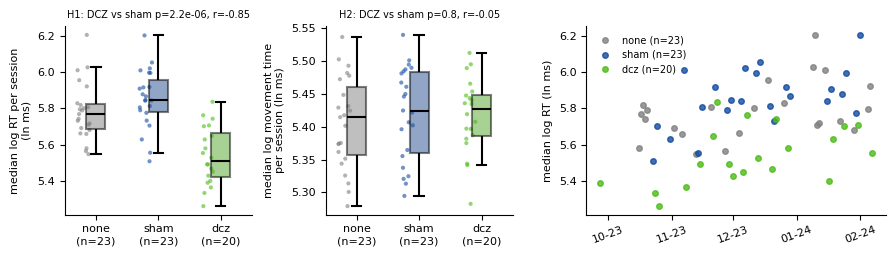

H1 log_rt: median RT none 320 ms, sham 346 ms, DCZ 247 ms | p=2.2e-06, r=-0.85, adjusted OLS p=1.1e-09
H2 log_mt: median RT none 225 ms, sham 227 ms, DCZ 227 ms | p=0.8, r=-0.05, adjusted OLS p=0.66


In [14]:
# H1: RT (lever validation -> release), H2: movement time (release -> first target touch)
fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), gridspec_kw={'width_ratios': [1, 1, 1.6]})
plot_dcz_panel(axs[0], dcz_sessions, 'log_rt', 'median log RT per session\n(ln ms)', 'H1')
plot_dcz_panel(axs[1], dcz_sessions, 'log_mt', 'median log movement time\nper session (ln ms)', 'H2')

# session RT across the recording period
ax = axs[2]
for injection in DCZ_ORDER:
    session_inj = dcz_sessions[dcz_sessions.injection == injection]
    ax.plot(session_inj['date'], session_inj['log_rt'], 'o', color=INJECTION_COLORS[injection], alpha=.8, markersize=4,
            label=f'{injection} (n={len(session_inj)})')
ax.set_ylabel('median log RT (ln ms)')
format_date_axis(ax)
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_dcz_A_rt_mt.svg', dpi=300)
plt.show()

for hypothesis, measure in [('H1', 'log_rt'), ('H2', 'log_mt')]:
    result = DCZ_RESULTS[(hypothesis, measure)]
    print(f'{hypothesis} {measure}: median RT none {np.exp(result["median_none"]):.0f} ms, sham {np.exp(result["median_sham"]):.0f} ms, '
          f'DCZ {np.exp(result["median_dcz"]):.0f} ms | p={result["p"]:.2g}, r={result["r"]:+.2f}, adjusted OLS p={result["p_adjusted_ols"]:.2g}')

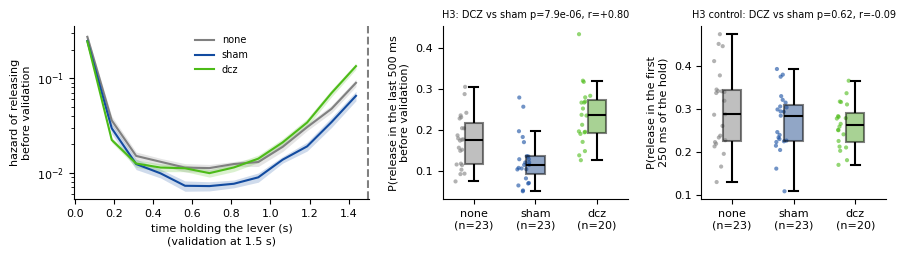

early lever releases per trial (median of sessions): {'none': 0.822, 'sham': 0.659, 'dcz': 0.946}
            measure  median_none  median_sham  median_dcz       r      p  p_adjusted_ols
late_release_hazard       0.1756       0.1141      0.2354  0.8000 0.0000          0.0000
        slip_hazard       0.2882       0.2849      0.2625 -0.0913 0.6177          0.7513


In [15]:
# H3: is the faster RT part of an earlier lever release overall (anticipation of the end of the 1.5 s hold)?
# hazard of releasing the lever before validation, in 125 ms bins of holding time, per session
bins = np.arange(0, 1.5 + 1e-9, 0.125)
hazards = pd.DataFrame([{'session': session, 'injection': session_holds['injection'].iloc[0], 'hold_time': start + 0.0625,
                         'hazard': release_hazard(session_holds, start, start + 0.125)}
                        for session, session_holds in dcz_holds.groupby('session') for start in bins[:-1]])

fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), gridspec_kw={'width_ratios': [1.6, 1, 1]})
ax = axs[0]
plot_condition_lines(ax, hazards, 'hold_time', 'hazard')
ax.set_yscale('log')
ax.axvline(1.5, color='grey', linestyle='--')
ax.set_xlabel('time holding the lever (s)\n(validation at 1.5 s)')
ax.set_ylabel('hazard of releasing\nbefore validation')
ax.legend(frameon=False, fontsize=7)
plot_dcz_panel(axs[1], dcz_sessions, 'late_release_hazard', 'P(release in the last 500 ms\nbefore validation)', 'H3')
plot_dcz_panel(axs[2], dcz_sessions, 'slip_hazard', 'P(release in the first\n250 ms of the hold)', 'H3 control')
plt.tight_layout()
plt.savefig('figs/yu_dcz_A_lever_hold.svg', dpi=300)
plt.show()

print('early lever releases per trial (median of sessions):', dcz_sessions.groupby('injection')['early_lever_release'].median().loc[DCZ_ORDER].round(3).to_dict())
print(pd.DataFrame([DCZ_RESULTS[key] for key in [('H3', 'late_release_hazard'), ('H3 control', 'slip_hazard')]]).round(4).to_string(index=False))

### B. Task engagement, outcome-driven disengagement and time-on-task (H4-H7)

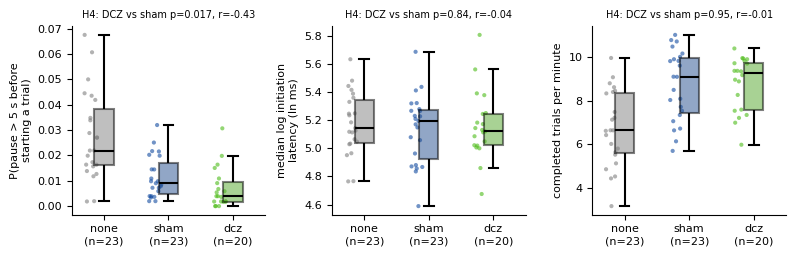

In [16]:
# H4: engagement: pauses before starting a trial (> 5 s), initiation latency, work rate
fig, axs = plt.subplots(1, 3, figsize=(8, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'pause_rate', 'P(pause > 5 s before\nstarting a trial)', 'H4')
plot_dcz_panel(axs[1], dcz_sessions, 'log_initiation', 'median log initiation\nlatency (ln ms)', 'H4')
plot_dcz_panel(axs[2], dcz_sessions, 'trials_per_min', 'completed trials per minute', 'H4')
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_engagement.svg', dpi=300)
plt.show()

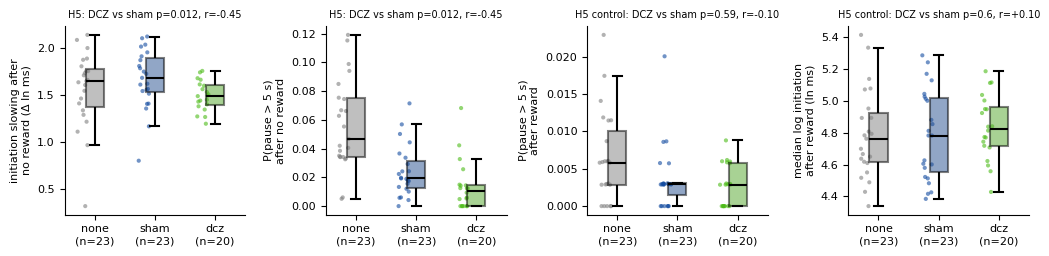

initiation after no reward, when the monkey then stays: sham 655 ms, DCZ 590 ms (p=0.023)
initiation after no reward, when the monkey then switches: sham 630 ms, DCZ 540 ms (p=0.19)


In [17]:
# H5: disengagement after a negative outcome: initiation latency and pauses after a rewarded / not rewarded trial
after = dcz_trials.dropna(subset=['prev_feedback']).groupby(['session', 'prev_feedback']).agg(
    log_initiation=('log_initiation', 'median'), pause=('pause', 'mean')).unstack('prev_feedback')
dcz_sessions['post_loss_slowing'] = after[('log_initiation', 0.0)] - after[('log_initiation', 1.0)]
dcz_sessions['pause_after_loss'] = after[('pause', 0.0)]
dcz_sessions['pause_after_reward'] = after[('pause', 1.0)]
dcz_sessions['log_initiation_after_reward'] = after[('log_initiation', 1.0)]

fig, axs = plt.subplots(1, 4, figsize=(10.5, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'post_loss_slowing', 'initiation slowing after\nno reward (Δ ln ms)', 'H5')
plot_dcz_panel(axs[1], dcz_sessions, 'pause_after_loss', 'P(pause > 5 s)\nafter no reward', 'H5')
plot_dcz_panel(axs[2], dcz_sessions, 'pause_after_reward', 'P(pause > 5 s)\nafter reward', 'H5 control')
plot_dcz_panel(axs[3], dcz_sessions, 'log_initiation_after_reward', 'median log initiation\nafter reward (ln ms)', 'H5 control')
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_post_loss.svg', dpi=300)
plt.show()

# is the faster re-engagement after no reward specific to the trials where the monkey then switches (deliberation)?
after_loss = dcz_trials[dcz_trials['prev_feedback'] == 0].groupby(['session', 'switch']).agg(
    injection=('injection', 'first'), log_initiation=('log_initiation', 'median')).reset_index()
for switch, label in [(0.0, 'stays'), (1.0, 'switches')]:
    dcz, sham = (after_loss.loc[(after_loss['switch'] == switch) & (after_loss.injection == injection), 'log_initiation'] for injection in ('dcz', 'sham'))
    print(f'initiation after no reward, when the monkey then {label}: sham {np.exp(sham.median()):.0f} ms, '
          f'DCZ {np.exp(dcz.median()):.0f} ms (p={stats.mannwhitneyu(dcz, sham).pvalue:.2g})')

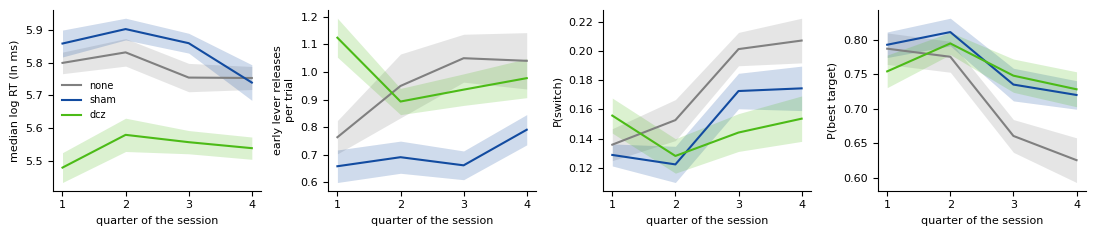

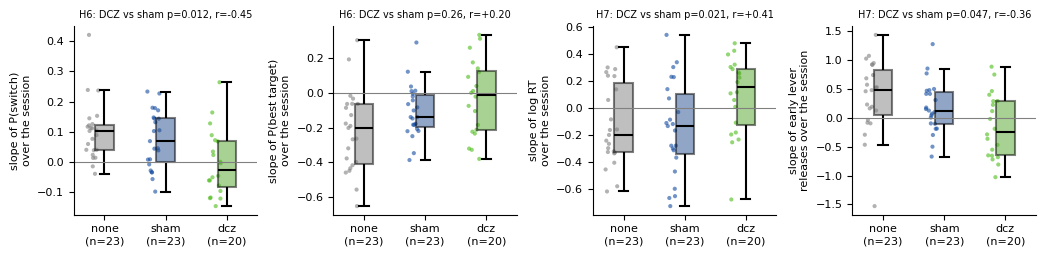

DCZ - sham, log_rt: Q1: -0.411 (p=1.2e-05) | Q2: -0.394 (p=5.6e-05) | Q3: -0.259 (p=1.3e-06) | Q4: -0.248 (p=0.0066)
DCZ - sham, early_lever_release: Q1: +0.475 (p=5.9e-05) | Q2: +0.165 (p=0.0059) | Q3: +0.332 (p=0.0013) | Q4: +0.161 (p=0.062)
DCZ - sham, switch: Q1: +0.021 (p=0.095) | Q2: +0.017 (p=0.49) | Q3: -0.027 (p=0.14) | Q4: +0.001 (p=0.35)
DCZ - sham, best: Q1: -0.043 (p=0.15) | Q2: -0.037 (p=0.19) | Q3: +0.011 (p=0.8) | Q4: +0.027 (p=0.78)


In [18]:
# H6 (time-on-task) and H7 (time course of the DCZ effect): measures per quarter of the session, and their slope
# over the session (linear fit against the fraction of the session completed)
quarters = dcz_trials.groupby(['session', 'session_quarter']).agg(
    injection=('injection', 'first'), log_rt=('log_rt', 'median'), early_lever_release=('n_early_lever_release', 'mean'),
    switch=('switch', 'mean'), best=('best', 'mean')).reset_index()

fig, axs = plt.subplots(1, 4, figsize=(11, 2.4))
for ax, (measure, ylabel) in zip(axs, {'log_rt': 'median log RT (ln ms)', 'early_lever_release': 'early lever releases\nper trial',
                                       'switch': 'P(switch)', 'best': 'P(best target)'}.items()):
    plot_condition_lines(ax, quarters, 'session_quarter', measure)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xlabel('quarter of the session')
    ax.set_ylabel(ylabel)
axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_time_course.svg', dpi=300)
plt.show()

for measure in ['log_rt', 'early_lever_release', 'switch', 'best']:
    column = {'early_lever_release': 'n_early_lever_release'}.get(measure, measure)
    dcz_sessions[f'{measure}_slope'] = dcz_trials.dropna(subset=[column]).groupby('session').apply(
        lambda session: np.polyfit(session['session_fraction'], session[column].astype(float), 1)[0])

fig, axs = plt.subplots(1, 4, figsize=(10.5, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'switch_slope', 'slope of P(switch)\nover the session', 'H6')
plot_dcz_panel(axs[1], dcz_sessions, 'best_slope', 'slope of P(best target)\nover the session', 'H6')
plot_dcz_panel(axs[2], dcz_sessions, 'log_rt_slope', 'slope of log RT\nover the session', 'H7')
plot_dcz_panel(axs[3], dcz_sessions, 'early_lever_release_slope', 'slope of early lever\nreleases over the session', 'H7')
for ax in axs:
    ax.axhline(0, color='grey', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_B_slopes.svg', dpi=300)
plt.show()

# DCZ - sham difference of the session medians per quarter
for measure in ['log_rt', 'early_lever_release', 'switch', 'best']:
    rows = []
    for quarter, quarter_values in quarters.groupby('session_quarter'):
        dcz, sham = (quarter_values.loc[quarter_values.injection == injection, measure] for injection in ('dcz', 'sham'))
        rows.append(f'Q{quarter}: {dcz.median() - sham.median():+.3f} (p={stats.mannwhitneyu(dcz, sham).pvalue:.2g})')
    print(f'DCZ - sham, {measure}: ' + ' | '.join(rows))

### C. Learning, exploration and persistence (H8-H12)

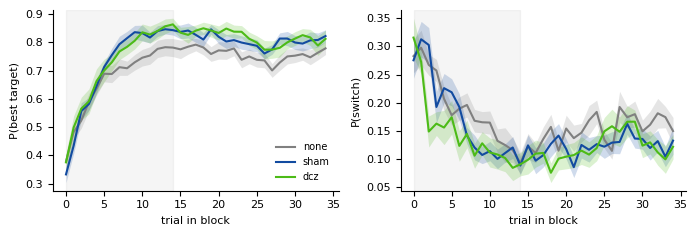

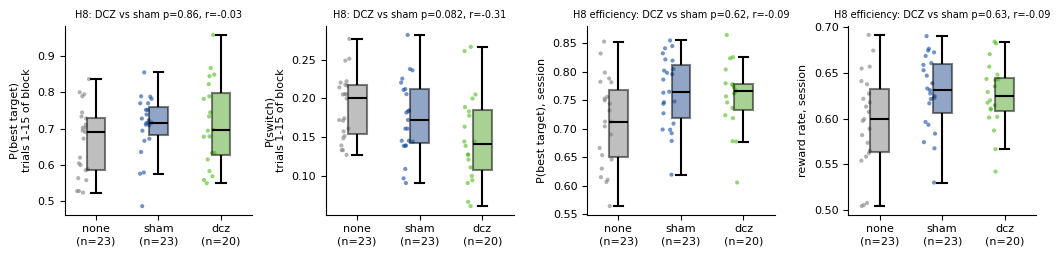

In [19]:
# H8: convergence to the best target after a block change: P(best target) and P(switch) by trial in block
# (first block of the session excluded: no preceding contingency change)
in_block = dcz_trials[dcz_trials['block_id'] > 0]
curves = in_block.groupby(['session', 'trial_id_in_block']).agg(injection=('injection', 'first'), best=('best', 'mean'),
                                                                 switch=('switch', 'mean')).reset_index()
curves = curves[curves['trial_id_in_block'] < 35]
early = in_block[in_block['trial_id_in_block'] < 15].groupby('session')
dcz_sessions['p_best_early_block'] = early['best'].mean()
dcz_sessions['p_switch_early_block'] = early['switch'].mean()

fig, axs = plt.subplots(1, 2, figsize=(7, 2.4))
for ax, (measure, ylabel) in zip(axs, {'best': 'P(best target)', 'switch': 'P(switch)'}.items()):
    plot_condition_lines(ax, curves, 'trial_id_in_block', measure)
    ax.axvspan(0, 14, color='grey', alpha=0.08)
    ax.set_xlabel('trial in block')
    ax.set_ylabel(ylabel)
axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_block_curves.svg', dpi=300)
plt.show()

fig, axs = plt.subplots(1, 4, figsize=(10.5, 2.6))
plot_dcz_panel(axs[0], dcz_sessions, 'p_best_early_block', 'P(best target)\ntrials 1-15 of block', 'H8')
plot_dcz_panel(axs[1], dcz_sessions, 'p_switch_early_block', 'P(switch)\ntrials 1-15 of block', 'H8')
plot_dcz_panel(axs[2], dcz_sessions, 'p_best', 'P(best target), session', 'H8 efficiency')
plot_dcz_panel(axs[3], dcz_sessions, 'reward_rate', 'reward rate, session', 'H8 efficiency')
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_block_measures.svg', dpi=300)
plt.show()

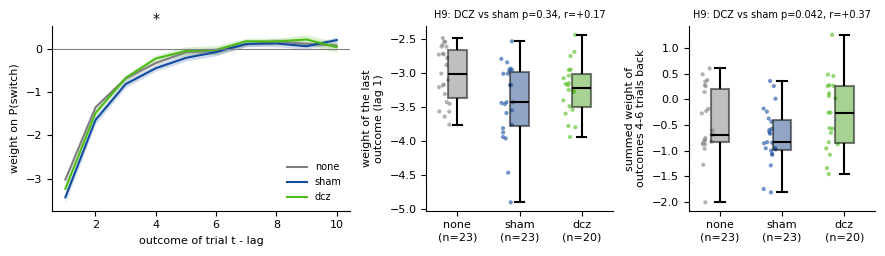

DCZ vs sham per lag (Mann-Whitney U): p = [0.336 0.247 0.238 0.02  0.066 0.742 0.401 0.779 0.301 0.238] 
  BH q = [0.48  0.48  0.48  0.201 0.33  0.779 0.501 0.779 0.48  0.48 ]
             R1    R2    R3    R4    R5    R6
injection                                    
none      -3.01 -1.36 -0.64 -0.40 -0.04  0.04
sham      -3.43 -1.66 -0.83 -0.45 -0.25 -0.20
dcz       -3.21 -1.57 -0.66 -0.10  0.01  0.01


In [20]:
# H9 (part 1): weight of past outcomes on switching, per session. Logistic regression as in the foraging paper (eq. 1,
# scikit-learn with class-balanced weights and the default L2 penalty, which also keeps sessions without any switch
# after some outcome patterns from diverging): P(switch_t) = σ(β0 + β1 R_t-1 + ... + β10 R_t-10)
from sklearn.linear_model import LogisticRegression

N_LAGS = 10
history_weights = {}
for session, session_trials in dcz_trials.groupby('session'):
    design = pd.DataFrame({f'R{lag}': session_trials['feedback'].shift(lag).values for lag in range(1, N_LAGS + 1)})
    design['switch'] = session_trials['switch'].values
    design = design.dropna()
    logistic = LogisticRegression(class_weight='balanced').fit(design.drop(columns='switch'), design['switch'].astype(int))
    history_weights[session] = pd.Series(logistic.coef_[0], index=[f'R{lag}' for lag in range(1, N_LAGS + 1)])
history_weights = pd.DataFrame(history_weights).T.join(dcz_sessions['injection'])
dcz_sessions['older_outcome_weight'] = history_weights[['R4', 'R5', 'R6']].sum(axis=1)   # outcomes 4-6 trials back
dcz_sessions['last_outcome_weight'] = history_weights['R1']

# weights per lag: DCZ vs sham per lag, Benjamini-Hochberg over the lags
lag_p = [stats.mannwhitneyu(*(history_weights.loc[history_weights.injection == injection, f'R{lag}'] for injection in ('dcz', 'sham'))).pvalue
         for lag in range(1, N_LAGS + 1)]
lag_q = multipletests(lag_p, method='fdr_bh')[1]

fig, axs = plt.subplots(1, 3, figsize=(9, 2.6), gridspec_kw={'width_ratios': [1.6, 1, 1]})
ax = axs[0]
weights_long = history_weights.reset_index(names='session').melt(id_vars=['session', 'injection'], value_vars=[f'R{lag}' for lag in range(1, N_LAGS + 1)],
                                                                 var_name='lag', value_name='weight')
weights_long['lag'] = weights_long['lag'].str[1:].astype(int)
plot_condition_lines(ax, weights_long, 'lag', 'weight')
for lag, p in zip(range(1, N_LAGS + 1), lag_p):
    if p < 0.05:
        ax.text(lag, 0.6, '*', ha='center', fontsize=10)
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xlabel('outcome of trial t - lag')
ax.set_ylabel('weight on P(switch)')
ax.legend(frameon=False, fontsize=7, loc='lower right')
plot_dcz_panel(axs[1], dcz_sessions, 'last_outcome_weight', 'weight of the last\noutcome (lag 1)', 'H9')
plot_dcz_panel(axs[2], dcz_sessions, 'older_outcome_weight', 'summed weight of\noutcomes 4-6 trials back', 'H9')
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_history_weights.svg', dpi=300)
plt.show()

print('DCZ vs sham per lag (Mann-Whitney U): p =', np.round(lag_p, 3), '\n  BH q =', np.round(lag_q, 3))
print(history_weights.groupby('injection')[[f'R{lag}' for lag in range(1, 7)]].median().loc[DCZ_ORDER].round(2).to_string())

In [21]:
# model fits per session (maximum likelihood): foraging model and inferential RL model of the foraging paper
# (eq. 4-9). Grid search over all parameters at once, then local refinement (~2 min for all sessions)
import math


def foraging_loglik_grid(choices, rewards, alphas, betas, taus):
    '''Log-likelihood of choices 2..n of the foraging model for every (beta, alpha, tau). V is reset to tau after a switch.'''
    alpha_grid, tau_grid = np.meshgrid(alphas, taus, indexing='ij')
    stay = choices[1:] == choices[:-1]
    values = np.empty((len(stay),) + alpha_grid.shape)
    value = tau_grid + alpha_grid * (rewards[0] - tau_grid)  # first trial: no previous choice, treated as a switch
    for t in range(1, len(choices)):
        values[t - 1] = value
        value = value + alpha_grid * (rewards[t] - value) if stay[t - 1] else tau_grid + alpha_grid * (rewards[t] - tau_grid)
    loglik = np.empty((len(betas),) + alpha_grid.shape)
    for i, beta in enumerate(betas):
        z = beta * (values - tau_grid)  # p(stay) = σ(β(V - τ)), p(each other target) = (1 - p(stay)) / 2
        loglik[i] = np.where(stay[:, None, None], -np.logaddexp(0, -z), -np.logaddexp(0, z) - math.log(2)).sum(0)
    return loglik


def foraging_nll(params, choices, rewards):
    alpha, beta, tau = params
    value, nll = tau + alpha * (rewards[0] - tau), 0.0
    for t in range(1, len(choices)):
        z = beta * (value - tau)
        if choices[t] == choices[t - 1]:
            nll += math.log1p(math.exp(-z)) if z > -30 else -z
            value += alpha * (rewards[t] - value)
        else:
            nll += (math.log1p(math.exp(z)) if z < 30 else z) + math.log(2)
            value = tau + alpha * (rewards[t] - tau)
    return nll


def rl_loglik_grid(choices, rewards, alphas, betas, kappas):
    '''Log-likelihood of choices 2..n of the inferential RL model (softmax with stickiness) for every (alpha, beta, kappa).'''
    n = len(choices)
    q_values, q = np.empty((n, len(alphas), 3)), np.full((len(alphas), 3), 1 / 3)
    for t in range(n):
        q_values[t] = q
        target = np.full(3, 1.0 - rewards[t])  # unchosen targets are updated with the inverse reward
        target[choices[t]] = rewards[t]
        q = q + alphas[:, None] * (target - q)
    q_values = q_values[1:, :, None, :]
    previous = np.eye(3)[choices[:-1]][:, None, None, :]
    chosen = choices[1:][:, None, None, None]
    loglik = np.empty((len(alphas), len(betas), len(kappas)))
    for j, beta in enumerate(betas):
        logits = beta * q_values + kappas[None, None, :, None] * previous
        loglik[:, j, :] = (np.take_along_axis(logits, np.broadcast_to(chosen, logits.shape[:-1] + (1,)), axis=3)[..., 0]
                           - np.logaddexp.reduce(logits, axis=3)).sum(0)
    return loglik


def rl_nll(params, choices, rewards):
    alpha, beta, kappa = params
    q, nll = [1 / 3] * 3, 0.0
    for t in range(len(choices)):
        if t > 0:
            logits = [beta * q[k] + (kappa if k == choices[t - 1] else 0.0) for k in range(3)]
            top = max(logits)
            nll -= logits[choices[t]] - top - math.log(sum(math.exp(logit - top) for logit in logits))
        q = [q[k] + alpha * ((rewards[t] if k == choices[t] else 1.0 - rewards[t]) - q[k]) for k in range(3)]
    return nll


def fit_model(loglik_grid, nll, grids, bounds, choices, rewards, grid_order):
    '''Best grid point, then L-BFGS-B refinement. grid_order: positions of the parameters in the grid axes.'''
    loglik = loglik_grid(choices, rewards, *grids)
    best = np.unravel_index(np.argmax(loglik), loglik.shape)
    start = [grids[i][best[grid_order[i]]] for i in range(3)]
    return optimize.minimize(nll, start, args=(choices, rewards), bounds=bounds, method='L-BFGS-B')


model_fits = {}
for session, session_trials in dcz_trials.groupby('session'):
    choices, rewards = session_trials['target'].astype(int).values - 1, session_trials['feedback'].astype(float).values
    foraging = fit_model(foraging_loglik_grid, foraging_nll,
                         [np.logspace(-2, 0, 20), np.logspace(-0.5, 2, 20), np.linspace(0.02, 0.98, 20)],
                         [(0.005, 1), (0.1, 300), (0.005, 0.995)], choices, rewards, grid_order=[1, 0, 2])
    rl = fit_model(rl_loglik_grid, rl_nll, [np.logspace(-2, 0, 20), np.logspace(-0.5, 2, 20), np.linspace(-2, 6, 17)],
                   [(0.005, 1), (0.1, 300), (-5, 15)], choices, rewards, grid_order=[0, 1, 2])
    n = len(choices) - 1
    model_fits[session] = {'foraging_alpha': foraging.x[0], 'foraging_beta': foraging.x[1], 'foraging_tau': foraging.x[2],
                           'foraging_lpt': np.exp(-foraging.fun / n), 'rl_alpha': rl.x[0], 'rl_beta': rl.x[1],
                           'rl_kappa': rl.x[2], 'rl_lpt': np.exp(-rl.fun / n)}
model_fits = pd.DataFrame(model_fits).T
dcz_sessions = dcz_sessions.drop(columns=model_fits.columns, errors='ignore').join(model_fits)
dcz_sessions['log_foraging_beta'] = np.log(dcz_sessions['foraging_beta'])
dcz_sessions['log_rl_beta'] = np.log(dcz_sessions['rl_beta'])

print('likelihood per trial (median over sessions):')
print(dcz_sessions.groupby('injection')[['foraging_lpt', 'rl_lpt']].median().loc[DCZ_ORDER].round(3).to_string())

likelihood per trial (median over sessions):
           foraging_lpt  rl_lpt
injection                      
none              0.665   0.644
sham              0.727   0.695
dcz               0.715   0.692


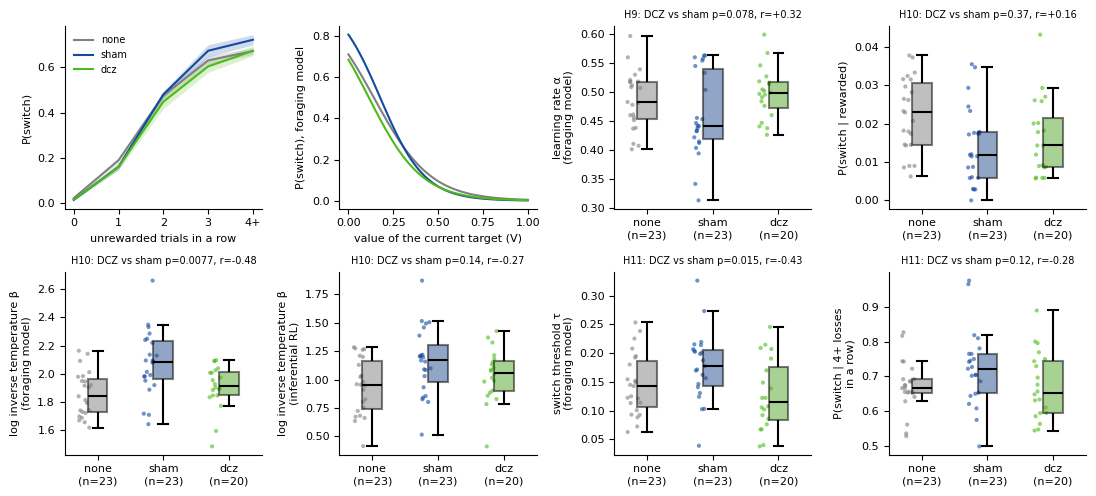

P(switch) by unrewarded trials in a row (median of sessions):
               0      1      2      3      4
injection                                   
none       0.023  0.190  0.469  0.640  0.667
sham       0.012  0.156  0.500  0.649  0.722
dcz        0.014  0.150  0.451  0.618  0.653
rl_alpha: sham 0.572, DCZ 0.573, p=0.36
rl_kappa: sham 2.360, DCZ 2.729, p=0.12
Spearman correlation of the foraging parameters over sessions:
                   foraging_alpha  log_foraging_beta  foraging_tau
foraging_alpha               1.00              -0.39         -0.34
log_foraging_beta           -0.39               1.00          0.44
foraging_tau                -0.34               0.44          1.00


In [22]:
# H9 (part 2): learning rate; H10: decision noise / random (value-free) exploration; H11: persistence (switch threshold)
def consecutive_losses(feedback):
    '''Number of unrewarded trials in a row before each trial.'''
    losses, count = [], 0
    for outcome in feedback:
        losses.append(count)
        count = count + 1 if outcome == 0 else 0
    return losses


dcz_trials['losses_before'] = dcz_trials.groupby('session')['feedback'].transform(lambda feedback: consecutive_losses(feedback.values))
dcz_trials['losses_bin'] = np.minimum(dcz_trials['losses_before'], 4)
loss_curves = dcz_trials.dropna(subset=['switch']).groupby(['session', 'losses_bin']).agg(
    injection=('injection', 'first'), switch=('switch', 'mean')).reset_index()
switch_by_losses = loss_curves.pivot(index='session', columns='losses_bin', values='switch')
dcz_sessions['win_shift'] = switch_by_losses[0]          # switching after a reward: value-free random exploration
dcz_sessions['switch_after_4_losses'] = switch_by_losses[4]

fig, axs = plt.subplots(2, 4, figsize=(11, 5))
ax = axs[0, 0]
plot_condition_lines(ax, loss_curves, 'losses_bin', 'switch')
ax.set_xticks(range(5), ['0', '1', '2', '3', '4+'])
ax.set_xlabel('unrewarded trials in a row')
ax.set_ylabel('P(switch)')
ax.legend(frameon=False, fontsize=7)

# fitted switching function of the foraging model: P(switch) = 1 - σ(β(V - τ)), median parameters per condition
ax = axs[0, 1]
value = np.linspace(0, 1, 101)
for injection in DCZ_ORDER:
    params = dcz_sessions[dcz_sessions.injection == injection][['foraging_beta', 'foraging_tau']].median()
    ax.plot(value, 1 - 1 / (1 + np.exp(-params['foraging_beta'] * (value - params['foraging_tau']))), color=INJECTION_COLORS[injection], label=injection)
ax.set_xlabel('value of the current target (V)')
ax.set_ylabel('P(switch), foraging model')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plot_dcz_panel(axs[0, 2], dcz_sessions, 'foraging_alpha', 'learning rate α\n(foraging model)', 'H9')
plot_dcz_panel(axs[0, 3], dcz_sessions, 'win_shift', 'P(switch | rewarded)', 'H10')
plot_dcz_panel(axs[1, 0], dcz_sessions, 'log_foraging_beta', 'log inverse temperature β\n(foraging model)', 'H10')
plot_dcz_panel(axs[1, 1], dcz_sessions, 'log_rl_beta', 'log inverse temperature β\n(inferential RL)', 'H10')
plot_dcz_panel(axs[1, 2], dcz_sessions, 'foraging_tau', 'switch threshold τ\n(foraging model)', 'H11')
plot_dcz_panel(axs[1, 3], dcz_sessions, 'switch_after_4_losses', 'P(switch | 4+ losses\nin a row)', 'H11')
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_models.svg', dpi=300)
plt.show()

print('P(switch) by unrewarded trials in a row (median of sessions):')
print(switch_by_losses.join(dcz_sessions['injection']).groupby('injection').median().loc[DCZ_ORDER].round(3).to_string())
for measure in ['rl_alpha', 'rl_kappa']:
    result = dcz_test(dcz_sessions, measure)
    DCZ_RESULTS[('H10/H11 RL', measure)] = result
    print(f'{measure}: sham {result["median_sham"]:.3f}, DCZ {result["median_dcz"]:.3f}, p={result["p"]:.2g}')
print('Spearman correlation of the foraging parameters over sessions:')
print(dcz_sessions[['foraging_alpha', 'log_foraging_beta', 'foraging_tau']].corr(method='spearman').round(2).to_string())

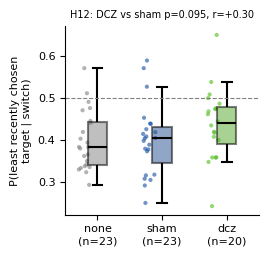

one-sample Wilcoxon vs 0.5: {'none': 0.0, 'sham': 0.0, 'dcz': 0.0045}


In [23]:
# H12: directed exploration: when switching, does the monkey go to the less recently chosen of the two other targets?
def p_switch_to_least_recent(targets):
    last_chosen, choices_least_recent = {1: -1, 2: -1, 3: -1}, []
    for t, target in enumerate(targets):
        if t > 0 and target != targets[t - 1]:
            others = [k for k in (1, 2, 3) if k != targets[t - 1]]
            if last_chosen[others[0]] != last_chosen[others[1]]:
                choices_least_recent.append(target == min(others, key=last_chosen.get))
        last_chosen[target] = t
    return np.mean(choices_least_recent)


dcz_sessions['switch_to_least_recent'] = dcz_trials.groupby('session')['target'].apply(lambda targets: p_switch_to_least_recent(targets.astype(int).values))

fig, ax = plt.subplots(1, 1, figsize=(2.8, 2.6))
plot_dcz_panel(ax, dcz_sessions, 'switch_to_least_recent', 'P(least recently chosen\ntarget | switch)', 'H12')
ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_C_directed_exploration.svg', dpi=300)
plt.show()
print('one-sample Wilcoxon vs 0.5:', {injection: round(stats.wilcoxon(dcz_sessions.loc[dcz_sessions.injection == injection, 'switch_to_least_recent'] - 0.5).pvalue, 4)
                                      for injection in DCZ_ORDER})

### Summary of the DCZ vs sham tests

In [24]:
# all DCZ vs sham tests, Benjamini-Hochberg FDR over all of them
summary = pd.DataFrame([{'hypothesis': hypothesis, **result} for (hypothesis, _), result in DCZ_RESULTS.items()])
summary['q_fdr'] = multipletests(summary['p'], method='fdr_bh')[1]
summary = summary[['hypothesis', 'measure', 'median_none', 'median_sham', 'median_dcz', 'r', 'p', 'q_fdr', 'p_adjusted_ols']]
summary.style.format({column: '{:.3g}' for column in summary.columns[2:]}).apply(
    lambda row: ['font-weight: bold' if row['q_fdr'] < 0.05 else '' for _ in row], axis=1)

,hypothesis,measure,median_none,median_sham,median_dcz,r,p,q_fdr,p_adjusted_ols
0,H1,log_rt,5.77,5.85,5.51,-0.848,2.18e-06,6.54e-05,1.14e-09
1,H2,log_mt,5.41,5.42,5.43,-0.0478,0.798,0.887,0.665
2,H3,late_release_hazard,0.176,0.114,0.235,0.8,7.89e-06,0.000118,1.47e-07
3,H3 control,slip_hazard,0.288,0.285,0.262,-0.0913,0.618,0.733,0.751
4,H4,pause_rate,0.0219,0.00903,0.00392,-0.428,0.017,0.0636,0.0431
5,H4,log_initiation,5.14,5.19,5.13,-0.0391,0.836,0.894,0.807
6,H4,trials_per_min,6.64,9.1,9.27,-0.013,0.951,0.951,0.544
7,H5,post_loss_slowing,1.64,1.68,1.49,-0.452,0.0117,0.0619,0.0294
8,H5,pause_after_loss,0.0467,0.0192,0.0108,-0.448,0.0124,0.0619,0.0466
9,H5 control,pause_after_reward,0.00581,0.00293,0.00288,-0.0978,0.586,0.733,0.373


## (7) Original hypotheses (exploratory)

Hypotheses O1-O6 are not taken from the manuscript or its discussion; they follow from the results of (6). They use the data and the helpers of (6). The DCZ vs sham tests are the same as in (6) (session values, two-sided Mann-Whitney U, rank-biserial r), and they form a separate FDR family (summary table at the end of this section).

In [25]:
# (7) helpers: tests of the original hypotheses, collected separately from (6)
import statsmodels.api as sm
from sklearn.mixture import GaussianMixture

ORIGINAL_RESULTS = {}  # {(hypothesis, measure): {'test', 'values', 'effect', 'p'}}


def plot_original_panel(ax, sessions, measure, ylabel, hypothesis, fmt='{:.3g}'):
    '''Boxplot of a session measure (none, sham, DCZ) with the DCZ vs sham test, stored in ORIGINAL_RESULTS.'''
    plot_box_with_scatter(sessions, measure, ax, order=DCZ_ORDER)
    result = dcz_test(sessions, measure)
    ORIGINAL_RESULTS[(hypothesis, measure)] = {
        'test': 'DCZ vs sham, Mann-Whitney U (r)', 'effect': result['r'], 'p': result['p'],
        'values': f'sham {fmt.format(result["median_sham"])} → DCZ {fmt.format(result["median_dcz"])} (none {fmt.format(result["median_none"])})'}
    ax.set_ylabel(ylabel)
    ax.set_title(f'{hypothesis}: DCZ vs sham p={result["p"]:.2g}, r={result["r"]:+.2f}', fontsize=7)
    return result


dcz_trials['rt_ms'] = np.exp(dcz_trials['log_rt'])

### O1. Does DCZ add anticipatory guesses, or accelerate the whole release process?

The shorter RT under DCZ could come from more fast anticipatory releases (guessing the time of the validation, without waiting for its sound), or from an acceleration of all releases, including the slow ones that react to the validation sound. Two readouts: the deciles of the RT distribution (shift function), and a two-component Gaussian mixture of log RT per session (fast and slow releases).

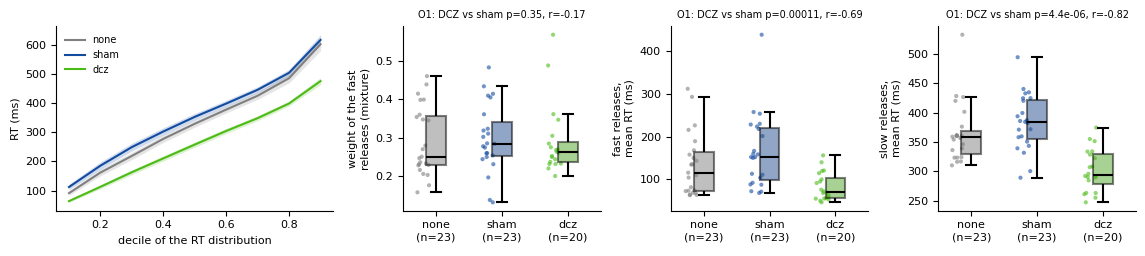

RT deciles (ms), median over sessions:
             0.1    0.2    0.3    0.4    0.5    0.6    0.7    0.8    0.9
injection                                                               
none        82.0  148.0  201.0  271.0  320.0  369.0  410.0  462.0  581.0
sham       106.0  181.0  246.0  306.0  346.0  393.0  441.0  495.0  600.0
dcz         60.0  108.0  154.0  202.0  247.0  303.0  341.0  394.0  465.0
DCZ - sham (ms): [-46.0, -73.0, -92.0, -104.0, -98.0, -89.0, -100.0, -101.0, -135.0]
DCZ / sham     : [0.57, 0.6, 0.63, 0.66, 0.72, 0.77, 0.77, 0.8, 0.77]
DCZ vs sham p per decile: [6e-06, 1.4e-05, 1.5e-05, 6e-06, 2e-06, 1e-06, 1e-06, 0.0, 1e-06]


In [26]:
# shift function: deciles of the RT distribution per session
deciles = np.round(np.arange(0.1, 0.91, 0.1), 1)
rt_deciles = dcz_trials.groupby('session')['rt_ms'].quantile(deciles).unstack().join(dcz_sessions['injection'])
decile_long = rt_deciles.reset_index().melt(id_vars=['session', 'injection'], var_name='decile', value_name='rt_ms')

# two-component Gaussian mixture of log RT per session: weight and mean of the fast and of the slow releases
mixture = {}
for session, session_trials in dcz_trials.groupby('session'):
    gm = GaussianMixture(2, n_init=5, random_state=0).fit(session_trials[['log_rt']].values)
    fast, slow = np.argsort(gm.means_.ravel())
    mixture[session] = {'fast_weight': gm.weights_[fast], 'fast_mean_ms': np.exp(gm.means_[fast, 0]), 'slow_mean_ms': np.exp(gm.means_[slow, 0])}
dcz_sessions = dcz_sessions.drop(columns=['fast_weight', 'fast_mean_ms', 'slow_mean_ms'], errors='ignore').join(pd.DataFrame(mixture).T.astype(float))

fig, axs = plt.subplots(1, 4, figsize=(11.5, 2.6), gridspec_kw={'width_ratios': [1.4, 1, 1, 1]})
ax = axs[0]
plot_condition_lines(ax, decile_long, 'decile', 'rt_ms')
ax.set_xlabel('decile of the RT distribution')
ax.set_ylabel('RT (ms)')
ax.legend(frameon=False, fontsize=7)
plot_original_panel(axs[1], dcz_sessions, 'fast_weight', 'weight of the fast\nreleases (mixture)', 'O1')
plot_original_panel(axs[2], dcz_sessions, 'fast_mean_ms', 'fast releases,\nmean RT (ms)', 'O1', '{:.0f}')
plot_original_panel(axs[3], dcz_sessions, 'slow_mean_ms', 'slow releases,\nmean RT (ms)', 'O1', '{:.0f}')
plt.tight_layout()
plt.savefig('figs/yu_dcz_O1_rt_distribution.svg', dpi=300)
plt.show()

decile_medians = rt_deciles.groupby('injection').median().loc[DCZ_ORDER]
decile_p = [stats.mannwhitneyu(*(rt_deciles.loc[rt_deciles.injection == injection, d] for injection in ('dcz', 'sham'))).pvalue for d in deciles]
print('RT deciles (ms), median over sessions:')
print(decile_medians.round(0).to_string())
print('DCZ - sham (ms):', (decile_medians.loc['dcz'] - decile_medians.loc['sham']).round(0).tolist())
print('DCZ / sham     :', (decile_medians.loc['dcz'] / decile_medians.loc['sham']).round(2).tolist())
print('DCZ vs sham p per decile:', np.round(decile_p, 6).tolist())

### O2. Are the extra premature lever releases a failure of error correction?

The MCC is involved in performance monitoring, so activating its noradrenergic input could impair the correction after a timing error. If so, a premature lever release should more often be followed by another one. Alternatively, DCZ affects only the first attempt to hold the lever in a trial, and the correction after an error is intact.

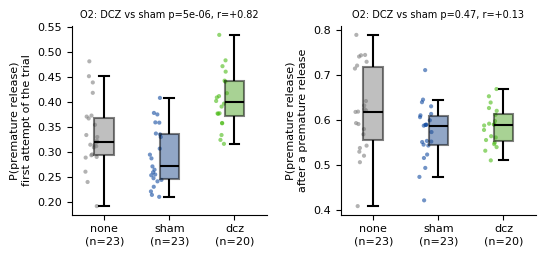

In [27]:
# lever hold attempts in order within each trial (from (6)): premature release on the first attempt, and after a premature release
attempts = dcz_holds.copy()
attempts['attempt'] = attempts.groupby(['session', 'trial_start_time']).cumcount()
attempts['premature'] = (~attempts['validated']).astype(float)
attempts['previous_premature'] = attempts.groupby(['session', 'trial_start_time'])['premature'].shift(1)
dcz_sessions['premature_first_attempt'] = attempts[attempts['attempt'] == 0].groupby('session')['premature'].mean()
dcz_sessions['premature_after_premature'] = attempts[attempts['previous_premature'] == 1].groupby('session')['premature'].mean()

fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6))
plot_original_panel(axs[0], dcz_sessions, 'premature_first_attempt', 'P(premature release)\nfirst attempt of the trial', 'O2')
plot_original_panel(axs[1], dcz_sessions, 'premature_after_premature', 'P(premature release)\nafter a premature release', 'O2')
plt.tight_layout()
plt.savefig('figs/yu_dcz_O2_timing_errors.svg', dpi=300)
plt.show()

### O3. Does DCZ advance the commitment to the choice?

While holding the lever, the monkey sometimes touches a target (codes 111/112/113, the event codes give which target). If the faster release reflects an earlier commitment to the choice, these premature target touches should be more frequent under DCZ, and on switch trials they should more often point to the new target instead of the previous one.

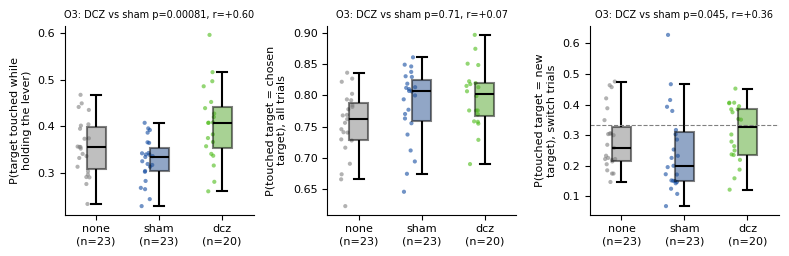

switch trials with an premature target touch per session (median): 43.0


In [28]:
def get_premature_target_touches(session):
    '''Targets touched before the lever validation (111/112/113 -> target 1/2/3), per trial of one session.'''
    raw = load_raw_behav_csv_yuri(session).to_numpy()
    rows = []
    for trial_events in reformat_behav(raw)['behav_events']:
        codes = trial_events[:, 0].astype(int)
        before_validation = codes[:np.argmax(codes == 62)] if (codes == 62).any() else codes
        touched = before_validation[np.isin(before_validation, [111, 112, 113])] - 110
        rows.append({'session': session, 'trial_start_time': round(trial_events[0, 1], 4),
                     'has_premature_touch': len(touched) > 0, 'last_premature_target': touched[-1] if len(touched) else np.nan})
    return pd.DataFrame(rows)


premature_touches = pd.concat([get_premature_target_touches(session) for session in dcz_sessions.index])
touches = dcz_trials.merge(premature_touches, on=['session', 'trial_start_time'], how='left', validate='one_to_one')
with_touch = touches[touches['has_premature_touch']]
dcz_sessions['p_premature_target_touch'] = touches.groupby('session')['has_premature_touch'].mean()
dcz_sessions['touch_is_choice'] = with_touch.groupby('session').apply(lambda t: (t['last_premature_target'] == t['target']).mean())
dcz_sessions['touch_is_new_target'] = with_touch[with_touch['switch'] == 1].groupby('session').apply(lambda t: (t['last_premature_target'] == t['target']).mean())

fig, axs = plt.subplots(1, 3, figsize=(8, 2.6))
plot_original_panel(axs[0], dcz_sessions, 'p_premature_target_touch', 'P(target touched while\nholding the lever)', 'O3')
plot_original_panel(axs[1], dcz_sessions, 'touch_is_choice', 'P(touched target = chosen\ntarget), all trials', 'O3')
plot_original_panel(axs[2], dcz_sessions, 'touch_is_new_target', 'P(touched target = new\ntarget), switch trials', 'O3')
axs[2].axhline(1 / 3, color='grey', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_O3_early_commitment.svg', dpi=300)
plt.show()
print('switch trials with an premature target touch per session (median):', with_touch[with_touch['switch'] == 1].groupby('session').size().median())

### O4. Does DCZ decouple the speed of the response from the decision variables?

Normally the RT carries information about the decision: the release is faster when the current target has a high value, and slower before a switch or a worse choice. A value-independent energization would speed up all releases alike and weaken these relations. To avoid a dilution by anticipatory releases (which cannot carry this information), only the slow, reactive releases (RT ≥ 150 ms) are used. The value of the current target before each trial comes from the foraging model with the session's fitted α and τ (see (6)).

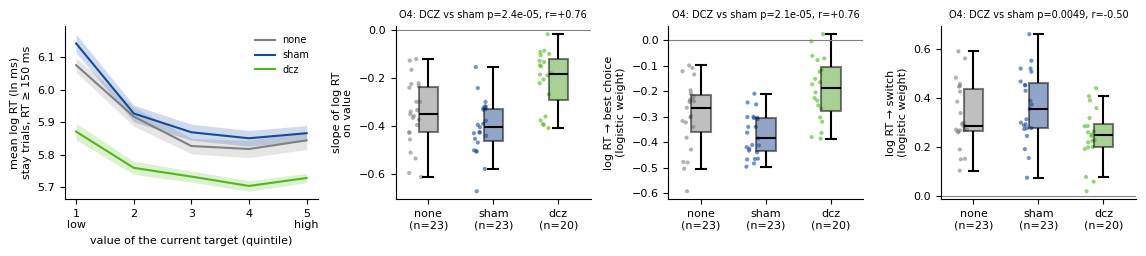

SD of log RT of the reactive releases: sham 0.461, DCZ 0.437 (p=0.01)


In [29]:
def foraging_values(choices, rewards, alpha, tau):
    '''Value of the current target before each trial in the foraging model (NaN for the first trial).'''
    values, value = np.full(len(choices), np.nan), tau + alpha * (rewards[0] - tau)
    for t in range(1, len(choices)):
        values[t] = value
        value = value + alpha * (rewards[t] - value) if choices[t] == choices[t - 1] else tau + alpha * (rewards[t] - tau)
    return values


for session, index in dcz_trials.groupby('session').groups.items():
    session_trials = dcz_trials.loc[index]
    dcz_trials.loc[index, 'value'] = foraging_values(session_trials['target'].values, session_trials['feedback'].values,
                                                     dcz_sessions.loc[session, 'foraging_alpha'], dcz_sessions.loc[session, 'foraging_tau'])

reactive = dcz_trials[dcz_trials['rt_ms'] >= 150].copy()
reactive['z_log_rt'] = reactive.groupby('session')['log_rt'].transform(lambda x: (x - x.mean()) / x.std())
coupling = {}
for session, session_trials in reactive.groupby('session'):
    stay = session_trials[(session_trials['switch'] == 0) & session_trials['value'].notna()]
    with_switch = session_trials.dropna(subset=['switch'])
    coupling[session] = {
        'rt_value_slope': np.polyfit(stay['value'], stay['log_rt'], 1)[0],
        'rt_best_coupling': sm.Logit(with_switch['best'], sm.add_constant(with_switch['z_log_rt'])).fit(disp=0).params['z_log_rt'],
        'rt_switch_coupling': sm.Logit(with_switch['switch'], sm.add_constant(with_switch['z_log_rt'])).fit(disp=0).params['z_log_rt'],
        'reactive_log_rt_sd': session_trials['log_rt'].std()}
dcz_sessions = dcz_sessions.drop(columns=list(next(iter(coupling.values()))), errors='ignore').join(pd.DataFrame(coupling).T)

# log RT by value quintile (stay trials, reactive releases)
stay = reactive[(reactive['switch'] == 0) & reactive['value'].notna()].copy()
stay['value_bin'] = stay.groupby('session')['value'].transform(lambda v: pd.qcut(v, 5, labels=False, duplicates='drop'))
value_curves = stay.groupby(['session', 'value_bin']).agg(injection=('injection', 'first'), log_rt=('log_rt', 'mean')).reset_index()

fig, axs = plt.subplots(1, 4, figsize=(11.5, 2.6), gridspec_kw={'width_ratios': [1.3, 1, 1, 1]})
ax = axs[0]
plot_condition_lines(ax, value_curves, 'value_bin', 'log_rt')
ax.set_xticks(range(5), ['1\nlow', '2', '3', '4', '5\nhigh'])
ax.set_xlabel('value of the current target (quintile)')
ax.set_ylabel('mean log RT (ln ms)\nstay trials, RT ≥ 150 ms')
ax.legend(frameon=False, fontsize=7)
plot_original_panel(axs[1], dcz_sessions, 'rt_value_slope', 'slope of log RT\non value', 'O4')
plot_original_panel(axs[2], dcz_sessions, 'rt_best_coupling', 'log RT → best choice\n(logistic weight)', 'O4')
plot_original_panel(axs[3], dcz_sessions, 'rt_switch_coupling', 'log RT → switch\n(logistic weight)', 'O4')
for ax in axs[1:]:
    ax.axhline(0, color='grey', linewidth=0.8)
plt.tight_layout()
plt.savefig('figs/yu_dcz_O4_vigor_decoupling.svg', dpi=300)
plt.show()

# control: a weaker relation could also come from a compressed RT range under DCZ
result = dcz_test(dcz_sessions, 'reactive_log_rt_sd')
print(f'SD of log RT of the reactive releases: sham {result["median_sham"]:.3f}, DCZ {result["median_dcz"]:.3f} (p={result["p"]:.2g})')

### O5. Is the DCZ effect stable over the months of injections?

Repeated chemogenetic activation could lose efficacy over time (tolerance), or its behavioral effect could grow (sensitization). For each DCZ session, the effect is measured against the sham sessions within ±7 days, and its trend over the successive DCZ sessions is tested.

log_rt_effect: effect present (Wilcoxon vs 0) p=3.8e-06, same sign in 19/19 DCZ sessions, trend over sessions rho=-0.13 (p=0.59)
late_release_effect: effect present (Wilcoxon vs 0) p=7.6e-06, same sign in 18/19 DCZ sessions, trend over sessions rho=-0.16 (p=0.5)


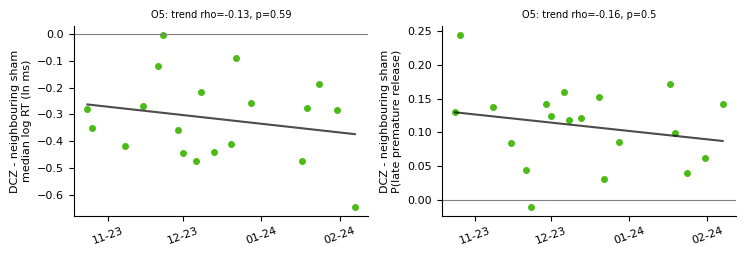

In [30]:
neighbour_effects = []
for session, row in dcz_sessions[dcz_sessions.injection == 'dcz'].sort_values('date').iterrows():
    neighbours = dcz_sessions[(dcz_sessions.injection == 'sham') & ((dcz_sessions['date'] - row['date']).abs() <= pd.Timedelta(days=7))]
    if len(neighbours) > 0:
        neighbour_effects.append({'session': session, 'date': row['date'],
                                  'log_rt_effect': row['log_rt'] - neighbours['log_rt'].mean(),
                                  'late_release_effect': row['late_release_hazard'] - neighbours['late_release_hazard'].mean()})
neighbour_effects = pd.DataFrame(neighbour_effects)
neighbour_effects['days'] = (neighbour_effects['date'] - neighbour_effects['date'].min()).dt.days

fig, axs = plt.subplots(1, 2, figsize=(7.5, 2.6))
for ax, (measure, ylabel) in zip(axs, {'log_rt_effect': 'DCZ - neighbouring sham\nmedian log RT (ln ms)',
                                        'late_release_effect': 'DCZ - neighbouring sham\nP(late premature release)'}.items()):
    ax.plot(neighbour_effects['date'], neighbour_effects[measure], 'o', color=INJECTION_COLORS['dcz'], markersize=4)
    fit = np.polyfit(neighbour_effects['days'], neighbour_effects[measure], 1)
    ax.plot(neighbour_effects['date'], np.polyval(fit, neighbour_effects['days']), color='black', alpha=0.7)
    ax.axhline(0, color='grey', linewidth=0.8)
    rho, p_trend = stats.spearmanr(neighbour_effects['days'], neighbour_effects[measure])
    p_present = stats.wilcoxon(neighbour_effects[measure]).pvalue
    n_consistent = int((np.sign(neighbour_effects[measure]) == np.sign(neighbour_effects[measure].median())).sum())
    ax.set_title(f'O5: trend rho={rho:+.2f}, p={p_trend:.2g}', fontsize=7)
    ax.set_ylabel(ylabel)
    format_date_axis(ax)
    ORIGINAL_RESULTS[('O5', f'{measure} trend')] = {'test': 'trend over DCZ sessions, Spearman (rho)', 'effect': rho, 'p': p_trend,
                                                   'values': f'median effect {neighbour_effects[measure].median():+.3f}; same sign in {n_consistent}/{len(neighbour_effects)} DCZ sessions'}
    print(f'{measure}: effect present (Wilcoxon vs 0) p={p_present:.2g}, same sign in {n_consistent}/{len(neighbour_effects)} DCZ sessions, '
          f'trend over sessions rho={rho:+.2f} (p={p_trend:.2g})')
plt.tight_layout()
plt.savefig('figs/yu_dcz_O5_stability.svg', dpi=300)
plt.show()

### O6. Does the DCZ effect carry over to the next day?

If the activation of the pathway had lasting (e.g. plasticity-related) consequences, sham sessions on the day after a DCZ session would differ from sham sessions after a day without injection. Note: sham sessions after DCZ are mostly Thursdays, sham sessions after no injection mostly Tuesdays.

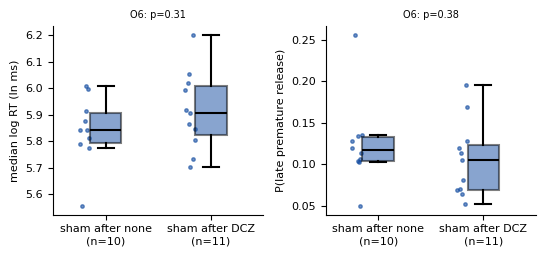

weekdays, sham after DCZ: {'Thursday': 8, 'Wednesday': 2, 'Friday': 1} | sham after none: {'Tuesday': 9, 'Wednesday': 1}


In [31]:
by_date = dcz_sessions.sort_values('date')
previous_day = by_date['injection'].shift(1).where(by_date['date'].diff().dt.days == 1)  # condition of the previous day, if consecutive
sham_next_day = by_date[(by_date.injection == 'sham') & previous_day.isin(['dcz', 'none'])].assign(previous=previous_day)

fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6))
for ax, (measure, ylabel) in zip(axs, {'log_rt': 'median log RT (ln ms)', 'late_release_hazard': 'P(late premature release)'}.items()):
    groups = [sham_next_day.loc[sham_next_day.previous == previous, measure] for previous in ('none', 'dcz')]
    ax.boxplot(groups, positions=[0, 1], widths=0.3, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=INJECTION_COLORS['sham'], alpha=0.5, edgecolor='black', linewidth=1.5),
               whiskerprops=dict(color='black', linewidth=1.5), capprops=dict(color='black', linewidth=1.5),
               medianprops=dict(color='black', linewidth=1.5))
    for i, values in enumerate(groups):
        ax.scatter(i - 0.2 + np.random.default_rng(i).uniform(-0.05, 0.05, len(values)), values, color=INJECTION_COLORS['sham'], s=6, alpha=0.6)
    p = stats.mannwhitneyu(groups[1], groups[0]).pvalue
    ax.set_xticks([0, 1], [f'sham after none\n(n={len(groups[0])})', f'sham after DCZ\n(n={len(groups[1])})'])
    ax.set_ylabel(ylabel)
    ax.set_title(f'O6: p={p:.2g}', fontsize=7)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ORIGINAL_RESULTS[('O6', measure)] = {'test': 'sham after DCZ vs sham after none, Mann-Whitney U', 'effect': np.nan, 'p': p,
                                         'values': f'after none {groups[0].median():.3g} → after DCZ {groups[1].median():.3g}'}
plt.tight_layout()
plt.savefig('figs/yu_dcz_O6_carryover.svg', dpi=300)
plt.show()
print('weekdays, sham after DCZ:', sham_next_day[sham_next_day.previous == 'dcz']['date'].dt.day_name().value_counts().to_dict(),
      '| sham after none:', sham_next_day[sham_next_day.previous == 'none']['date'].dt.day_name().value_counts().to_dict())

### Summary of the original hypotheses

In [32]:
# tests of (7), Benjamini-Hochberg FDR within this exploratory family
original_summary = pd.DataFrame([{'hypothesis': hypothesis, 'measure': measure, **result} for (hypothesis, measure), result in ORIGINAL_RESULTS.items()])
original_summary['q_fdr'] = multipletests(original_summary['p'], method='fdr_bh')[1]
original_summary = original_summary[['hypothesis', 'measure', 'test', 'values', 'effect', 'p', 'q_fdr']]
original_summary.style.format({'effect': '{:+.2f}', 'p': '{:.2g}', 'q_fdr': '{:.2g}'}, na_rep='').apply(
    lambda row: ['font-weight: bold' if row['q_fdr'] < 0.05 else '' for _ in row], axis=1)

,hypothesis,measure,test,values,effect,p,q_fdr
0,O1,fast_weight,"DCZ vs sham, Mann-Whitney U (r)",sham 0.284 → DCZ 0.262 (none 0.25),-0.17,0.35,0.52
1,O1,fast_mean_ms,"DCZ vs sham, Mann-Whitney U (r)",sham 152 → DCZ 70 (none 115),-0.69,0.00011,0.00034
2,O1,slow_mean_ms,"DCZ vs sham, Mann-Whitney U (r)",sham 384 → DCZ 294 (none 359),-0.82,4.4e-06,3.7e-05
3,O2,premature_first_attempt,"DCZ vs sham, Mann-Whitney U (r)",sham 0.271 → DCZ 0.399 (none 0.319),+0.82,5e-06,3.7e-05
4,O2,premature_after_premature,"DCZ vs sham, Mann-Whitney U (r)",sham 0.587 → DCZ 0.589 (none 0.618),+0.13,0.47,0.58
5,O3,p_premature_target_touch,"DCZ vs sham, Mann-Whitney U (r)",sham 0.335 → DCZ 0.408 (none 0.356),+0.60,0.00081,0.002
6,O3,touch_is_choice,"DCZ vs sham, Mann-Whitney U (r)",sham 0.806 → DCZ 0.803 (none 0.762),+0.07,0.71,0.71
7,O3,touch_is_new_target,"DCZ vs sham, Mann-Whitney U (r)",sham 0.2 → DCZ 0.327 (none 0.259),+0.36,0.045,0.084
8,O4,rt_value_slope,"DCZ vs sham, Mann-Whitney U (r)",sham -0.405 → DCZ -0.182 (none -0.351),+0.76,2.4e-05,9e-05
9,O4,rt_best_coupling,"DCZ vs sham, Mann-Whitney U (r)",sham -0.385 → DCZ -0.189 (none -0.265),+0.76,2.1e-05,9e-05


## Report: behavioral effects of the chemogenetic activation of the LC/NA→MCC pathway (DCZ), monkey YU

**Data and statistics.** 20 DCZ and 23 sham (saline) sessions, interleaved over the same weeks (Sep 2023 – Feb 2024), with 23 no-injection sessions for reference. Task parameters are identical in all sessions (lever hold 1.5 s, target hold 450 ms, session ends after 350 rewards; checked in the csv headers). One value per session, completed trials only. DCZ vs sham: two-sided Mann-Whitney U, rank-biserial r; robustness check by OLS adjusted for session date and weekday; Benjamini-Hochberg FDR over all 30 DCZ vs sham tests (q). All numbers below come from sections (6) and (7).

### Main effects of DCZ

1. **Earlier release of the lever, not faster movement.** RT (lever validation → release) drops from 346 to 247 ms (−29 %), and the probability of releasing the lever in the last 500 ms before the 1.5 s validation doubles (0.11 → 0.24). Movement time and accidental early slips are unchanged. These are the only effects that survive the FDR correction (q < 0.001). DCZ seems to shift the timing of the lever release earlier, as in anticipation or urgency, rather than speeding up the movement or making the animal more impulsive in general.
2. **Less disengagement after unrewarded trials** (nominal p ≈ 0.01, q ≈ 0.06). After an unrewarded trial, the slowing before the next lever touch is smaller and long pauses (> 5 s) are about half as frequent. After rewarded trials nothing changes.
3. **More persistent, less drifting choice behavior, with unchanged efficiency** (nominal p < 0.05, q ≈ 0.06-0.13). Switching does not increase over the session under DCZ. The foraging model has a lower switch threshold and a lower inverse temperature, which means less switching when the current target has a low value. Outcomes 4-6 trials back weigh less on switching. The reward rate, P(best target) and the speed of finding the best target after a block change are unchanged.
4. **Energized but value-blind responses** (exploratory, section (7)). DCZ accelerates all lever releases, including those that react to the validation sound. The speed of the release no longer tracks the value of the current target or the upcoming choice as it does in sham sessions (q < 0.001). The effect is present in every DCZ session, without tolerance over the months.

### Hypotheses and results

**A. Energization of action**

- **H1. DCZ shortens decision RT.** Increasing NA makes monkeys execute trials faster and more consistently (Kaduk et al., 2023, as cited in the manuscript). Lowering NA with clonidine reduces energization (Jahn et al., 2018; Borderies et al., 2020), and LC neurons are sensitive to effort (Varazzani et al., 2015).
  Result: median RT 346 ms (sham) → 247 ms (DCZ), none 320 ms; p = 2×10⁻⁶, q < 0.001, r = −0.85, adjusted OLS p = 10⁻⁹. RT is also shorter in every quarter of the session. **Supported.**
- **H2. Motor execution is not affected** (cognitive vs motor dissociation proposed in the manuscript discussion).
  Result: movement time (release → first target touch) 227 vs 227 ms; p = 0.80, r = −0.05. **Supported:** the speeding is specific to the decision / release.
- **H3. The faster RT is part of an earlier lever release overall (temporal anticipation, urgency).** Pupil-linked (putatively noradrenergic) gain modulation produces time-dependent urgency (Murphy et al., 2016). The opposite prediction comes from rodents, where raising NA reduces premature responses: atomoxetine (Robinson et al., 2008) and optogenetic LC stimulation (Bari et al., 2020). In mice, response inhibition depends on the LC→ventrolateral OFC projection, not on LC→dmPFC (Bari et al., 2020).
  Result: P(release in the last 500 ms of the hold | held until then) 0.11 → 0.24 (none 0.18); p = 8×10⁻⁶, q < 0.001, r = +0.80. Releases in the first 250 ms of the hold (slips) are unchanged (0.28 vs 0.26, p = 0.62). Early lever releases per trial rise from 0.66 to 0.95 (session medians).
  **Supported.** The extra lever presses under DCZ are re-presses after anticipatory releases, not extra trial initiations, so they should not be read as more engagement. RT is measured on validated holds only, so moving the earliest releases before validation makes the RT decrease a conservative estimate.

**B. Engagement and time-on-task**

- **H4. DCZ increases task engagement:** fewer pauses, faster trial initiation, higher work rate. MCC→dlPFC activation increases engagement (Gandaux et al., 2025); the adaptive gain theory links LC mode to task engagement (Aston-Jones & Cohen, 2005).
  Result:
  - Pauses > 5 s before touching the lever: 0.9 % → 0.4 % of trials (none 2.2 %); p = 0.017, q = 0.064, adjusted p = 0.043.
  - Median initiation latency: unchanged (p = 0.84).
  - Completed trials per minute: 9.1 vs 9.3 (p = 0.95).

  **Partially supported** (fewer pauses only). The work rate is constrained by the task: the session ends after a fixed number of rewards, and DCZ trials include extra lever re-holds.
- **H5. DCZ reduces the disengagement caused by negative outcomes.** MCC processes negative feedback to drive adaptation (Quilodran et al., 2008), and NA mobilizes resources to face challenges (Jahn et al., 2018; Borderies et al., 2020).
  Result:
  - Slowing of trial initiation after an unrewarded trial: 1.68 → 1.49 ln units (p = 0.012, q = 0.062, adjusted p = 0.029).
  - Pauses after an unrewarded trial: 1.9 % → 1.1 % (p = 0.012, q = 0.062).
  - After rewarded trials, neither initiation latency (p = 0.60) nor pauses (p = 0.59) change.
  - Initiation after an unrewarded trial is shorter both when the monkey then stays (655 → 590 ms, p = 0.023) and when it switches (630 → 540 ms, p = 0.19). This points to a general re-engagement after losses, not a faster deliberation before switching.

  **Supported (nominally).**
- **H6. DCZ reduces time-on-task effects** (manuscript discussion). Disengagement over time on task goes with decreasing pupil-linked arousal (Hopstaken et al., 2015).
  Result:
  - Slope of P(switch) over the session: +0.069 (sham) vs −0.026 (DCZ); p = 0.012, q = 0.062, adjusted p = 0.019.
  - Slope of P(best target): −0.14 vs −0.01, p = 0.26 (n.s.).

  **Partially supported:** switching stays stable over the session under DCZ.
- **H7. Time course consistent with DCZ pharmacology.** DCZ acts within minutes and its effect lasts several hours (Nagai et al., 2020).
  Result:
  - The DCZ − sham RT difference is present from the first quarter of the session (−0.41 ln units) and smaller in the last quarter (−0.25, still p = 0.007). Slope of RT over the session: p = 0.021, q = 0.071.
  - The early-lever-release excess is largest in the first quarter (+0.48 vs +0.16 per trial in the last quarter); slope p = 0.047.

  **Consistent:** rapid onset, and a decline within the ~1 h session. The interval between injection and session start is not in the data, so this could not be checked further.

**C. Learning, exploration and persistence**

- **H8. Faster convergence to the best target after a block change** (manuscript discussion). The network reset (Bouret & Sara, 2005) and unexpected uncertainty (Yu & Dayan, 2005) accounts predict faster adaptation to unsignaled changes.
  Result:
  - P(best target) in trials 1-15 of a block: 0.72 vs 0.70 (p = 0.87).
  - P(switch) in trials 1-15: 0.17 → 0.14 (p = 0.082, q = 0.19).
  - Session P(best target) and reward rate: unchanged (0.765 vs 0.765, 0.631 vs 0.625).

  **Not supported** for the speed of convergence and overall efficiency. Reduced early-block switching is a trend.
- **H9. More weight on recent outcomes.** The manuscript's logistic model suggests this, and pupil-linked arousal regulates the learning rate (Nassar et al., 2012). Method: switch regression on the last 10 outcomes, as in Ungvárszki et al. (2025) and Lau & Glimcher (2005).
  Result:
  - Weight of the last outcome: unchanged (p = 0.34).
  - Summed weight of outcomes 4-6 trials back: −0.83 → −0.26 (p = 0.042, q = 0.13; lag 4 alone p = 0.02 uncorrected).
  - Foraging-model learning rate α: 0.44 → 0.50 (p = 0.078).

  **Partially supported:** older outcomes are forgotten faster (shorter memory), rather than the last outcome being weighted more.
- **H10. DCZ changes decision noise / random exploration.** Predictions point both ways:
  - Increase: LC input to ACC switches rats into stochastic choice (Tervo et al., 2014); a high tonic LC mode promotes exploration (Aston-Jones & Cohen, 2005; Jepma & Nieuwenhuis, 2011).
  - Decrease: clonidine decreases choice variability (Jahn et al., 2018); atomoxetine reduces random exploration (Warren et al., 2017); propranolol reduces value-free random exploration (Dubois et al., 2021).

  Result:
  - Value-free switching (P(switch | rewarded)): 1.2 % vs 1.4 % (p = 0.37).
  - Foraging inverse temperature β: 8.0 → 6.8 (p = 0.008, q = 0.062, adjusted p = 0.009).
  - RL inverse temperature: 3.2 → 2.9 (p = 0.14).

  **Not supported for random exploration.** The lower β is better understood together with H11.
- **H11. DCZ changes persistence (switch threshold).** Adaptive gain theory predicts more disengagement from the current option; the manuscript discussion predicts reduced shifting.
  Result:
  - Foraging switch threshold τ: 0.18 → 0.12 (p = 0.015, q = 0.064, adjusted p = 0.005).
  - With the lower β, the fitted switching function reaches a lower maximal P(switch) when the current target's value is low, i.e. more persistence after repeated losses. P(switch | 4+ losses in a row): 0.72 → 0.65 (p = 0.125).
  - RL stickiness κ: 2.4 → 2.7 (p = 0.12).
  - β and τ are only moderately correlated across sessions (Spearman ρ = 0.44).

  **Partially supported, in the direction of more persistence**, against the adaptive gain prediction.
- **H12. Directed exploration is unchanged.** Atomoxetine affected random but not directed exploration (Warren et al., 2017; task logic: Wilson et al., 2014).
  Result: when switching, P(going to the less recently chosen target) is 0.40 (sham) vs 0.44 (DCZ), p = 0.095; below 0.5 in all conditions. **Supported (no significant change, trend).**

### Comparison with the claims of the manuscript discussion

| Claim | This analysis |
|---|---|
| Faster RT without a change in movement time | Reproduced (H1, H2) |
| More lever presses | Reproduced, but explained by anticipatory hold failures (H3) |
| Reduced time-on-task effects | Partly reproduced: switching does not drift over the session (H6) |
| Reduced shifting early in blocks | Trend only (H8, p = 0.08) |
| Faster convergence to the best target | Not reproduced (H8) |
| More weight on recent outcomes | Partly reproduced: older outcomes weigh less, the last outcome does not weigh more (H9) |

### Original hypotheses (exploratory)

These hypotheses are not taken from the manuscript or its discussion. I formulated them after the results above, so they are exploratory. The tests are the same as above (DCZ vs sham sessions), with a separate FDR correction over the 15 tests of this part (section (7) of the notebook).

- **O1. DCZ accelerates the whole release process, rather than adding anticipatory guesses.** The shorter RT could come from more releases that anticipate the validation (guesses made without waiting for its sound), or from faster releases overall, including those that react to the sound.
  Result:
  - Every decile of the RT distribution is shorter under DCZ, by 46 ms at the 10th percentile up to 135 ms at the 90th (p ≤ 2×10⁻⁵ for each decile).
  - A two-component mixture of log RT per session separates fast and slow releases. The share of fast releases is unchanged (0.28 vs 0.26, p = 0.35), but both kinds are earlier: fast releases 152 → 70 ms (p = 10⁻⁴), slow releases 384 → 294 ms (p = 4×10⁻⁶).

  **Supported:** the whole release process is accelerated, including the releases that react to the validation sound. DCZ does not simply add guesses.

- **O2. The extra premature lever releases do not come from a failure of error correction.** The MCC monitors performance, so activating its noradrenergic input could impair the correction after a timing error. If so, premature releases would repeat within a trial.
  Result: the probability of a premature release on the first attempt of a trial rises from 0.27 to 0.40 (p = 5×10⁻⁶, q < 0.001). After a premature release it is 0.59 in both conditions (p = 0.47).

  **Supported:** the correction after a premature release is intact. DCZ raises premature releases only when the monkey has not just made one.

- **O3. DCZ advances the commitment to the choice.** While holding the lever, the monkey sometimes touches a target (codes 111-113 give which one), which reveals the target it is preparing to choose. If DCZ advances the decision, these touches should be more frequent, and on switch trials they should more often point to the new target.
  Result:
  - Trials with a target touch while holding the lever: 34 % → 41 % (p = 8×10⁻⁴, q = 0.002).
  - The touched target is the chosen one in about 80 % of the trials in both conditions (p = 0.71).
  - On switch trials, the touched target is the new one in 20 % (sham) vs 33 % (DCZ) of the trials (p = 0.045, q = 0.08).

  **Partially supported:** premature target touches are more frequent, while the earlier commitment to switches is only a trend.

- **O4. DCZ decouples the speed of the response from the decision variables.** If the noradrenergic input adds a drive to act that does not depend on value, the RT should carry less information about the value of the current target and about the upcoming choice. Only the slow, reactive releases (RT ≥ 150 ms) are used, so that the extra fast releases cannot dilute these relations.
  Result:
  - On stay trials, the slope of log RT on the value of the current target (foraging model) is −0.41 under sham vs −0.18 under DCZ (p = 2×10⁻⁵, q < 0.001).
  - Under sham, slower releases go with worse choices and with switches. Under DCZ this relation is weaker: the logistic weight of log RT on choosing the best target goes from −0.39 to −0.19 (p = 2×10⁻⁵, q < 0.001), and on switching from +0.36 to +0.25 (p = 0.005, q = 0.01).
  - This is not an artefact of a compressed RT range: the SD of the reactive log RT is only 5 % smaller under DCZ (0.46 vs 0.44).

  **Supported, and the clearest new result.** Under DCZ the monkey releases the lever faster largely independently of the value of its choice and of the upcoming decision.

- **O5. The DCZ effect is stable over the months of injections.** Repeated chemogenetic activation could lose efficacy over time (tolerance) or gain it (sensitization).
  Result: compared with the sham sessions within ±7 days, RT is shorter in 19 of 19 DCZ sessions (median −0.28 ln units), and late premature releases are more frequent in 18 of 19. There is no trend over the ~4 months, either for RT (ρ = −0.13, p = 0.59) or for late premature releases (ρ = −0.16, p = 0.50).

  **Supported:** no tolerance or sensitization.

- **O6. The DCZ effect carries over to the next day.**
  Result: sham sessions on the day after a DCZ session (n = 11, mostly Thursdays) do not differ from sham sessions after a day without injection (n = 10, mostly Tuesdays). Median log RT is 5.91 vs 5.84 (p = 0.31), and late premature releases 0.105 vs 0.117 (p = 0.38).

  **Not supported:** no next-day carryover was detected, though the groups are small and differ in weekday.

**Synthesis.** The new results sharpen the picture of the effect on action. DCZ accelerates every lever release, both anticipatory and cue-reactive (O1). It raises premature releases only on the first hold attempt of a trial, while the correction after an error is intact (O2). Most importantly, it makes the speed of the response largely independent of the value of the choice and of the upcoming decision (O4). This is what a value-independent drive to act would produce: the activation of the noradrenergic input to the MCC energizes action initiation, while the choice computations themselves change only slightly (H8-H11). The effect is reproducible across all DCZ sessions, without tolerance (O5) and without next-day carryover (O6), so pooling the DCZ sessions is justified.

### Caveats

- A single animal: sessions are the replicates, so the effects generalize to this monkey's sessions only.
- Only H1 and H3 survive the FDR correction at q < 0.05. The cluster of effects at q ≈ 0.06-0.13 (H4-H6, H9-H11) is consistent in direction but should be confirmed, e.g. in the other monkeys or with a pre-specified test.
- *None* sessions are mostly Mondays after the weekend, so differences between none and the injection days cannot be attributed to the injection.
- The interval between injection and session start is not in the data. The within-session decline of the effect (H7) may reflect DCZ kinetics or an interaction with fatigue.
- Foraging-model parameters are fitted per session by maximum likelihood (grid search + L-BFGS-B), without hierarchical pooling. β and τ partly trade off, so the fitted switching function and the model-free loss curve are the more direct readouts.
- The original hypotheses O1-O6 were formulated after seeing the results of section (6), so they are exploratory and need confirmation in independent data.

### Sources

- Aston-Jones & Cohen (2005). An integrative theory of locus coeruleus-norepinephrine function: adaptive gain and optimal performance. *Annu Rev Neurosci*.
- Bari et al. (2020). Differential attentional control mechanisms by two distinct noradrenergic coeruleo-frontal cortical pathways. *PNAS* 117:29080-29089.
- Borderies, Bornert, Gilardeau & Bouret (2020). Pharmacological evidence for the implication of noradrenaline in effort. *PLoS Biol*, doi:10.1371/journal.pbio.3000793.
- Bouret & Sara (2005). Network reset: a simplified overarching theory of locus coeruleus noradrenaline function. *Trends Neurosci* 28:574-582, doi:10.1016/j.tins.2005.09.002.
- Dubois et al. (2021). Human complex exploration strategies are enriched by noradrenaline-modulated heuristics. *eLife* 10:e59907.
- Gandaux et al. (2025). *Curr Biol* (MCC→dlPFC pathway activation with DREADDs increases engagement in a foraging task).
- Hopstaken et al. (2015). A multifaceted investigation of the link between mental fatigue and task disengagement. *Psychophysiology* 52:305-315, doi:10.1111/psyp.12339.
- Jahn et al. (2018). Dual contributions of noradrenaline to behavioural flexibility and motivation. *Psychopharmacology* 235:2687-2702, doi:10.1007/s00213-018-4963-z.
- Jepma & Nieuwenhuis (2011). Pupil diameter predicts changes in the exploration-exploitation trade-off: evidence for the adaptive gain theory. *J Cogn Neurosci*.
- Kaduk et al. (2023), as cited in the manuscript discussion (not checked here).
- Lau & Glimcher (2005). Dynamic response-by-response models of matching behavior in rhesus monkeys. *J Exp Anal Behav* 84:555-579.
- Murphy, Boonstra & Nieuwenhuis (2016). Global gain modulation generates time-dependent urgency during perceptual choice in humans. *Nat Commun* 7:13526, doi:10.1038/ncomms13526.
- Nagai et al. (2020). Deschloroclozapine, a potent and selective chemogenetic actuator enables rapid neuronal and behavioral modulations in mice and monkeys. *Nat Neurosci* 23:1157-1167, doi:10.1038/s41593-020-0661-3.
- Nassar et al. (2012). Rational regulation of learning dynamics by pupil-linked arousal systems. *Nat Neurosci* 15:1040-1046, doi:10.1038/nn.3130.
- Quilodran, Rothé & Procyk (2008). Behavioral shifts and action valuation in the anterior cingulate cortex. *Neuron* 57:314-325, doi:10.1016/j.neuron.2007.11.031.
- Robinson et al. (2008). Similar effects of the selective noradrenaline reuptake inhibitor atomoxetine on three distinct forms of impulsivity in the rat. *Neuropsychopharmacology*.
- Tervo et al. (2014). Behavioral variability through stochastic choice and its gating by anterior cingulate cortex. *Cell*.
- Ungvárszki et al. (2025). Neural dynamics reveal foraging-like computations in the frontal cortex. *bioRxiv*, doi:10.1101/2025.09.29.679289.
- Varazzani, San-Galli, Gilardeau & Bouret (2015). Noradrenaline and dopamine neurons in the reward/effort trade-off: a direct electrophysiological comparison in behaving monkeys. *J Neurosci* 35:7866-7877, doi:10.1523/JNEUROSCI.0454-15.2015.
- Warren et al. (2017). The effect of atomoxetine on random and directed exploration in humans. *PLoS ONE*, doi:10.1371/journal.pone.0176034.
- Wilson et al. (2014). Humans use directed and random exploration to solve the explore-exploit dilemma. *J Exp Psychol Gen* 143:2074-2081, doi:10.1037/a0038199.
- Yu & Dayan (2005). Uncertainty, neuromodulation, and attention. *Neuron* 46:681-692.